# Bài 12 – Chuỗi thời gian II: ARIMA và dự báo

Notebook kiểm chứng **Bài 12** trên 3 bộ dữ liệu NI (Nile), AP (AirPassengers), DP (log giá DAX). Mỗi mục có đúng 6 tiểu mục theo đặc tả: *Nội dung lý thuyết*, *Cách triển khai*,
*Mã lệnh Python*, *Kết quả*, *Phân tích và diễn giải*, *Nhận xét*. Hai tiểu mục cuối để dạng khung `TODO(nhóm)`: mọi con số ở đây do code sinh ra,
phần diễn giải do nhóm viết.

Ký hiệu: **[D]** tính trên dữ liệu thật; **[M]** mô phỏng có điều khiển (seed 3179, `S.child_rng(...)`, kèm MCSE).
Hình lưu ở `reports/figures/` (PNG 300 dpi), bảng ở `reports/tables/` (csv, md, tex; tên ổn định).

*Cảnh báo của statsmodels* (khởi tạo tham số MA, hội tụ, nội suy p-value của KPSS) được ẩn có chủ ý; bài giảng cũng ghi nhận chúng không ảnh hưởng các con số.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import sys
import numpy as np, pandas as pd, scipy, statsmodels, matplotlib
import statsmodels.api as sm
import matplotlib.pyplot as plt
from IPython.display import display
from scipy import stats
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.statespace.structural import UnobservedComponents
from statsmodels.tsa.holtwinters import SimpleExpSmoothing
from statsmodels.tsa.stattools import acf, adfuller, kpss, coint
from statsmodels.stats.diagnostic import acorr_ljungbox

from as3179ts.config import SEED, AP_TRAIN_N, DP_TRAIN_N
from as3179ts.data import load_processed
from as3179ts import acf_tools as A, arma_tools as R, forecast_tools as F, evaluation as E, simulation as S
from as3179ts.plotting import save_figure, show_figure, acf_bars, panel_label, overlay_theory, BLUE, ORANGE, GREEN, RED, PURPLE, GREY
from as3179ts.reporting import save_table
pd.options.display.float_format = lambda v: f"{v:.4g}"
warnings.filterwarnings("ignore")  # statsmodels bật lại cảnh báo khi import nên tắt lại ở đây

print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__, "| scipy", scipy.__version__,
      "| statsmodels", statsmodels.__version__, "| matplotlib", matplotlib.__version__)
print("SEED =", SEED)
rng = np.random.default_rng(SEED)  # generator gốc; mỗi mục dùng S.child_rng(12, k) nên kết quả không phụ thuộc thứ tự chạy ô

DATA = {c: load_processed(c) for c in ("NI", "AP", "DP")}
NAMES = {"NI": "Nile", "AP": "AirPassengers (log, huấn luyện)", "DP": "log giá DAX"}
NI = DATA["NI"].flow.to_numpy()
AP = DATA["AP"].passengers.to_numpy(dtype=float)           # thang gốc, 144 tháng
LAP = DATA["AP"].log_passengers.to_numpy()                  # log, 144 tháng
TR = LAP[:AP_TRAIN_N]                                       # huấn luyện 120 tháng (1949–1958)
DAX = DATA["DP"].dax_close.to_numpy()
LD = DATA["DP"].log_close.to_numpy()                        # log giá, 1860 ngày giao dịch
SERIES = {"NI": NI, "AP": TR, "DP": LD}
TIME = {"NI": DATA["NI"].year.to_numpy(), "AP": 1949 + np.arange(120) / 12, "DP": DATA["DP"].t.to_numpy()}   # trục thời gian thật
XLAB = {"NI": "năm", "AP": "năm", "DP": "ngày giao dịch t"}
YLAB = {"NI": "lưu lượng (10⁸ m³)", "AP": "log(số hành khách)", "DP": "log DAX"}
PLAB = {"ma.L1": "θ", "ma.S.L12": "Θ (mùa vụ)", "ar.L1": "φ", "sigma2": "σ²", "x1": "c (độ trôi)", "const": "hằng số"}


def sig2(res):
    """σ̂² của kết quả ARIMA/SARIMAX (nằm trong params)."""
    return float(dict(zip(res.param_names, res.params))["sigma2"])


def lb(resid, H, model_df=0):
    r = acorr_ljungbox(resid, lags=[H], model_df=model_df)
    return float(r["lb_stat"].iloc[0]), float(r["lb_pvalue"].iloc[0])


def airline(z):
    """SARIMA(0,1,1)(0,1,1)₁₂ không hằng số (Bài 12, Mục 6)."""
    return SARIMAX(z, order=(0, 1, 1), trend="n", seasonal_order=(0, 1, 1, 12)).fit(disp=0)

Python 3.12.14 | numpy 2.5.5 | pandas 3.1.1 | scipy 1.18.1 | statsmodels 0.15.0 | matplotlib 3.11.2
SEED = 3179


## 12.1 Xu thế tất định và xu thế ngẫu nhiên; I(d)

*Bộ dữ liệu:* NI, AP, DP (cả 3)

### Nội dung lý thuyết

**Định nghĩa 1.** Dừng quanh xu thế: $Y_t=\mu_t+X_t$ ($X$ dừng yếu); tích hợp bậc $d$, $Y\sim I(d)$: $\nabla^dY_t$ dừng yếu với phương sai dài hạn $v\in(0,\infty)$ và
$\nabla^{d-1}Y_t$ không dừng. Cú sốc lên chuỗi dừng quanh xu thế tắt dần; cú sốc lên chuỗi I(1) dịch chuyển cả quỹ đạo tương lai. Bước ngẫu nhiên có trôi $Y_t=\delta+Y_{t-1}+\varepsilon_t$ là trường hợp điển hình của I(1).

### Cách triển khai

**[D]** Với mỗi bộ (AP: log, 120 tháng huấn luyện): vẽ chuỗi, ACF của chuỗi gốc, ACF của chuỗi sai phân $\nabla y$; thêm ACF của phần dư sau khi khử xu thế tuyến tính bằng OLS
(đối chứng với xu thế tất định). Bảng $\hat\rho(1)$, $\hat\rho(10)$ và độ lệch chuẩn. Sai phân mùa vụ của AP xem 12.10.

### Mã lệnh Python

In [2]:
fig, axes = plt.subplots(3, 3, figsize=(13, 8.8), gridspec_kw={"width_ratios": [1.5, 1, 1]}); rows = []
for i, (c, y) in enumerate(SERIES.items()):
    n = len(y); d1 = np.diff(y); t = np.arange(n)
    detr = y - np.polyval(np.polyfit(t, y, 1), t)
    axes[i, 0].plot(TIME[c], y, lw=0.9, color=BLUE); axes[i, 0].set(title=NAMES[c], xlabel=XLAB[c], ylabel=YLAB[c]); panel_label(axes[i, 0], "(" + "abc"[i] + ")")
    acf_bars(axes[i, 1], A.sample_acf(y, 30), n, f"{c}: ACF của chuỗi gốc y"); acf_bars(axes[i, 2], A.sample_acf(d1, 30), len(d1), f"{c}: ACF của sai phân ∇y")
    rows.append({"bộ": c, "n": n, "SD của y": y.std(ddof=1), "SD của ∇y": d1.std(ddof=1), "ρ̂(1) của y": A.sample_acf(y, 10)[1], "ρ̂(10) của y": A.sample_acf(y, 10)[10],
                 "ρ̂(1) sau khử xu thế OLS": A.sample_acf(detr, 10)[1], "ρ̂(10) sau khử xu thế OLS": A.sample_acf(detr, 10)[10], "ρ̂(1) của ∇y": A.sample_acf(d1, 10)[1]})
fig_path = save_figure(fig, "fig_b12_01_levels_vs_differences")
tab = save_table(pd.DataFrame(rows).set_index("bộ"), "tab_b12_01_levels_vs_differences")

### Kết quả

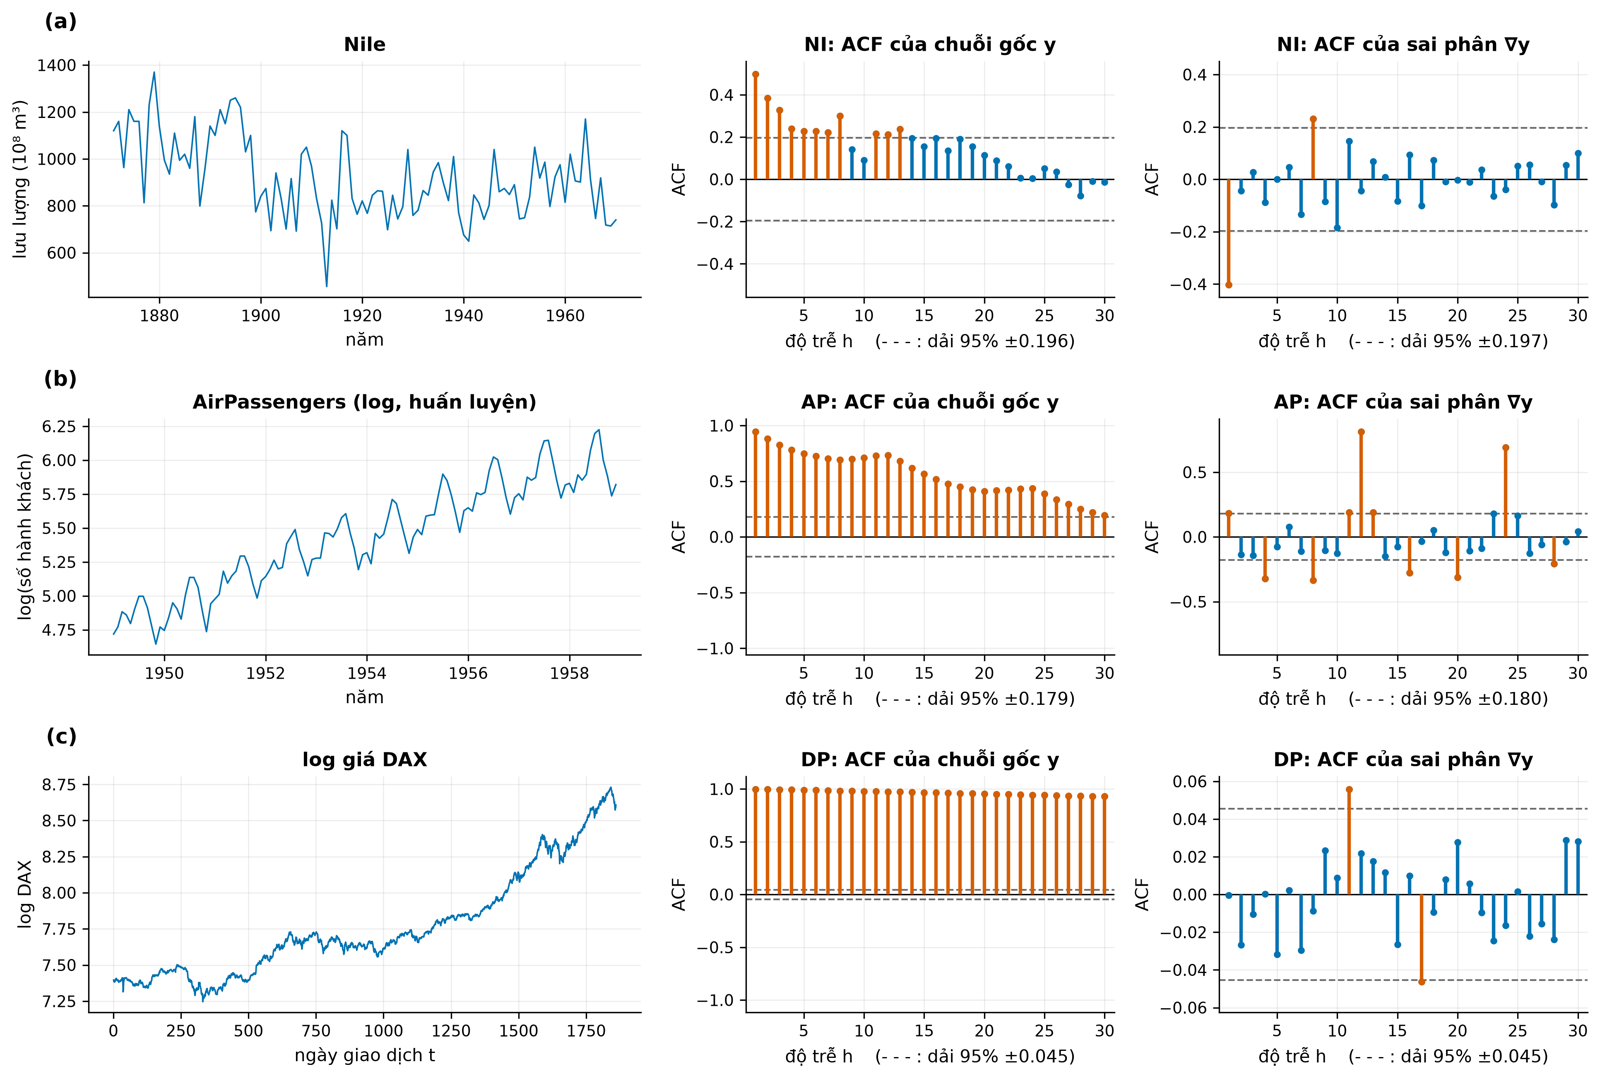

,n,SD của y,SD của ∇y,ρ̂(1) của y,ρ̂(10) của y,ρ̂(1) sau khử xu thế OLS,ρ̂(10) sau khử xu thế OLS,ρ̂(1) của ∇y
bộ,,,,,,,,
NI,100,169.2,168.1,0.4984,0.08979,0.3749,-0.06835,-0.402
AP,120,0.3917,0.1058,0.9455,0.7111,0.676,0.1839,0.1834
DP,1860,0.3632,0.0103,0.9979,0.9786,0.9958,0.9603,-0.0004346


In [3]:
show_figure(fig_path)
tab

### Phân tích và diễn giải

**TODO(nhóm):** viết 2–4 câu diễn giải kết quả ở trên, liên hệ trực tiếp với lý thuyết. Câu hỏi gợi ý:

- ACF của chuỗi gốc suy giảm chậm gần tuyến tính ở bộ nào? Một sai phân làm biểu đồ thay đổi ra sao?
- Khử xu thế bằng OLS có đưa ACF về dạng suy giảm nhanh không (dấu hiệu xu thế tất định) hay vẫn dai dẳng (xu thế ngẫu nhiên)?
- NI không thuộc hẳn loại nào (trung bình 1098 trước 1899, 850 sau đó). Điều này ảnh hưởng thế nào đến việc đọc ACF?

### Nhận xét

**TODO(nhóm):** kết quả có phù hợp lý thuyết không? Nếu lệch, do đặc điểm nào của dữ liệu?

## 12.2 Bước ngẫu nhiên

*Bộ dữ liệu:* DP (mô phỏng, tham số từ DP); NI, AP: giải thích

### Nội dung lý thuyết

**Định lý 1.** $Y_t=Y_0+\delta t+\sum_{j\le t}\varepsilon_j$: $EY_t=Y_0+\delta t$, $\operatorname{Var}Y_t=t\sigma^2$, $\operatorname{Cov}(Y_s,Y_t)=\min(s,t)\sigma^2$,
$\operatorname{Corr}(Y_t,Y_{t+h})=\sqrt{t/(t+h)}\to1$; $\hat\rho(h)\to1$ nên biểu đồ tương quan giảm rất chậm. Hệ quả: hồi quy giả mạo giữa hai bước ngẫu nhiên độc lập (Bài 11, Ví dụ 1.2).

### Cách triển khai

**[M]** Ước lượng $\hat\delta,\hat\sigma$ từ 1859 suất sinh lợi log của DP, mô phỏng $B=2000$ bước ngẫu nhiên dài 250: so $\operatorname{Var}Y_t$ với $t\hat\sigma^2$, $\operatorname{Corr}(Y_t,Y_{t+h})$ với $\sqrt{t/(t+h)}$;
ACF mẫu trung bình của bước ngẫu nhiên $n=200$. **Hồi quy giả mạo:** hai bước ngẫu nhiên độc lập $n=100$, OLS $Y$ theo $X$, tần suất bác bỏ $H_0:\beta_1=0$ ở 5%.
NI và AP không phải bước ngẫu nhiên (NI có đổi mức, AP có mùa vụ) nên không dùng làm "sự thật" mô phỏng.

### Mã lệnh Python

In [4]:
r = np.diff(LD); delta, sigma = r.mean(), r.std(ddof=1)
rng = S.child_rng(12, 2); B, T = 2000, 250
paths = np.array([S.simulate_random_walk(T, rng, delta, sigma) for _ in range(B)])   # Y_t, t = 1..T (Y_0 = 0)
ts = [1, 10, 50, 100, 250]
tab_var = pd.DataFrame({"t": ts, "t·σ̂² (lý thuyết)": [t * sigma ** 2 for t in ts], "Var mô phỏng": [paths[:, t - 1].var(ddof=1) for t in ts],
                        "E Yₜ = δ̂t": [delta * t for t in ts], "trung bình mô phỏng": [paths[:, t - 1].mean() for t in ts]}).set_index("t")
tab_var["tỷ số Var"] = tab_var["Var mô phỏng"] / tab_var["t·σ̂² (lý thuyết)"]
pairs = [(50, 10), (100, 50), (100, 150)]
tab_corr = pd.DataFrame({"(t, h)": [str(p) for p in pairs], "√(t/(t+h))": [np.sqrt(t / (t + h)) for t, h in pairs],
                         "tương quan mô phỏng": [np.corrcoef(paths[:, t - 1], paths[:, t + h - 1])[0, 1] for t, h in pairs]}).set_index("(t, h)")
tab_var = save_table(tab_var, "tab_b12_02_rw_variance"); tab_corr = save_table(tab_corr, "tab_b12_02_rw_correlation")
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.0)); tgrid = np.arange(1, T + 1)
axes[0].plot(tgrid, paths.var(axis=0, ddof=1), color=BLUE, label="Var mô phỏng (B = 2000)"); axes[0].plot(tgrid, tgrid * sigma ** 2, color=ORANGE, ls="--", label="t·σ̂² (lý thuyết)")
axes[0].set(xlabel="t (ngày giao dịch)", ylabel="Var Yₜ", title="Phương sai tăng tuyến tính theo t"); axes[0].legend(loc="upper left")
for pth in paths[:50]: axes[1].plot(tgrid, pth, lw=0.5, color=BLUE, alpha=0.5)
axes[1].plot(tgrid, delta * tgrid, color=RED, lw=1.8, label="E Yₜ = δ̂t"); axes[1].legend(loc="upper left")
axes[1].set(xlabel="t (ngày giao dịch)", ylabel="Yₜ (log giá, Y₀ = 0)", title="50 đường mô phỏng của bước ngẫu nhiên có trôi")
panel_label(axes[0], "(a)"); panel_label(axes[1], "(b)"); fig_path = save_figure(fig, "fig_b12_02_rw_variance")
rho_bar = np.mean([A.sample_acf(S.simulate_random_walk(200, rng, 0.0, 1.0), 20) for _ in range(B)], axis=0)
tab_rho = save_table(pd.DataFrame({"trung bình ρ̂(h), n = 200": rho_bar[[1, 2, 5, 10, 20]]}, index=pd.Index([1, 2, 5, 10, 20], name="h")), "tab_b12_02_rw_sample_acf")

In [5]:
rng = S.child_rng(12, 20); B, n = 2000, 100
crit = stats.t.ppf(0.975, n - 2); reject = 0
for _ in range(B):
    x, y = S.simulate_random_walk(n, rng), S.simulate_random_walk(n, rng)
    xc = x - x.mean(); b1 = (xc @ (y - y.mean())) / (xc @ xc)
    resid = (y - y.mean()) - b1 * xc; se = np.sqrt(resid @ resid / (n - 2) / (xc @ xc))
    reject += abs(b1 / se) > crit
tab_spur = save_table(pd.DataFrame({"tần suất bác bỏ β₁ = 0 (mức 5%)": [reject / B], "MCSE": [np.sqrt(reject / B * (1 - reject / B) / B)], "danh nghĩa": [0.05]},
                                   index=["hai bước ngẫu nhiên độc lập, n = 100"]), "tab_b12_02_spurious_regression")

### Kết quả

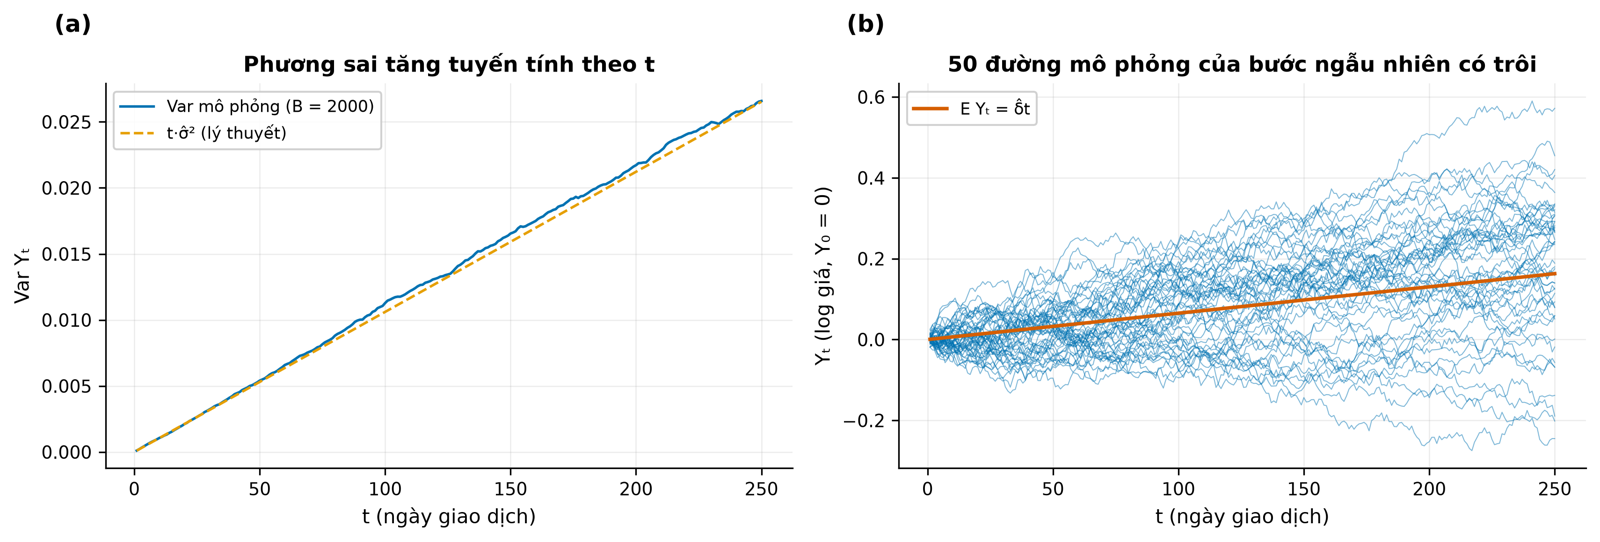

δ̂ = 0.000652, σ̂ = 0.010301 (từ 1859 suất sinh lợi log)


,t·σ̂² (lý thuyết),Var mô phỏng,E Yₜ = δ̂t,trung bình mô phỏng,tỷ số Var
t,,,,,
1,0.0001061,0.0001129,0.000652,0.0007104,1.064
10,0.001061,0.001065,0.00652,0.007506,1.004
50,0.005305,0.005405,0.0326,0.03306,1.019
100,0.01061,0.01128,0.0652,0.0673,1.063
250,0.02653,0.02658,0.163,0.1658,1.002


,√(t/(t+h)),tương quan mô phỏng
"(t, h)",,
"(50, 10)",0.9129,0.911
"(100, 50)",0.8165,0.8239
"(100, 150)",0.6325,0.6385


,"trung bình ρ̂(h), n = 200"
h,
1,0.963
2,0.9272
5,0.8253
10,0.6745
20,0.4319


,tần suất bác bỏ β₁ = 0 (mức 5%),MCSE,danh nghĩa
"hai bước ngẫu nhiên độc lập, n = 100",0.769,0.009424,0.05


In [6]:
show_figure(fig_path)
print(f'δ̂ = {delta:.6f}, σ̂ = {sigma:.6f} (từ {len(r)} suất sinh lợi log)')
display(tab_var)
display(tab_corr)
display(tab_rho)
tab_spur

### Phân tích và diễn giải

**TODO(nhóm):** viết 2–4 câu diễn giải kết quả ở trên, liên hệ trực tiếp với lý thuyết. Câu hỏi gợi ý:

- Var mô phỏng có tăng tuyến tính theo $t$ với hệ số $\hat\sigma^2$ không (tỷ số ≈ 1, tính đến MCSE ≈ $\sqrt{2/(B-1)}$)?
- Tương quan $\operatorname{Corr}(Y_t,Y_{t+h})$ mô phỏng có khớp $\sqrt{t/(t+h)}$; $\hat\rho(h)$ trung bình ≈ 0.96, …, 0.43 (bài giảng)?
- Tần suất bác bỏ trong hồi quy giả mạo là bao nhiêu so với 5%? Vì sao OLS ‘ngây thơ’ sai (Bài 11, Định lý 1 và Định nghĩa 2)?

### Nhận xét

**TODO(nhóm):** kết quả có phù hợp lý thuyết không? Nếu lệch, do đặc điểm nào của dữ liệu?

## 12.3 Sai phân sửa được gì và làm hỏng gì: sai phân quá mức

*Bộ dữ liệu:* NI, DP (AP: xem 12.10)

### Nội dung lý thuyết

**Mệnh đề 1.** $\nabla$ của chuỗi dừng có phương sai dài hạn $\sum_h\gamma_{\nabla X}(h)=0$ (sai phân quá mức). Nếu $X_t\sim WN$ thì $\nabla X_t$ là MA(1) với $\theta=-1$, $\rho(1)=-\tfrac12$,
đa thức MA có nghiệm trên vòng tròn đơn vị (không khả nghịch, $\hat\theta\to-1$). Chi phí: dự báo bước ngẫu nhiên cho nhiễu trắng có sai số $2\sigma^2$ (gấp đôi); thiếu sai phân: dự báo bước ngẫu nhiên bằng
$\bar Y_n$ có $\operatorname{Var}=\sigma^2\{(n-1)(2n-1)/(6n)+h\}$ ($33.8\sigma^2$ khi $n=100,h=1$).

### Cách triển khai

**[D]** NI và DP: $\hat\rho(1)$, độ lệch chuẩn, phương sai dài hạn (Bartlett cắt cụt, $K=\lfloor4(n/100)^{2/9}\rfloor$) và $\hat\theta$ của MA(1) cho $y$, $\nabla y$, $\nabla^2y$.
**[M]** nhiễu trắng $n=400$, $B=1000$: $\hat\rho(1)$ của $\nabla\varepsilon$; sai số dự báo của bước ngẫu nhiên (nhiễu trắng) và của $\bar Y_n$ (bước ngẫu nhiên), $B=5000$.

### Mã lệnh Python

In [7]:
def long_run_var(w):
    n = len(w); K = int(np.floor(4 * (n / 100) ** (2 / 9))); g = A.sample_autocov(w, K)
    return g[0] + 2 * np.sum((1 - np.arange(1, K + 1) / (K + 1)) * g[1:])
rows = []
for c, y in (("NI", NI), ("DP", LD)):
    for name, w, trend in (("∇y", np.diff(y), "c"), ("∇²y (quá mức)", np.diff(y, 2), "n")):
        m = ARIMA(w, order=(0, 0, 1), trend=trend).fit(); th = m.maparams[0]
        rows.append({"bộ": c, "chuỗi": name, "n": len(w), "sd": w.std(ddof=1), "ρ̂(1)": A.sample_acf(w, 1)[1], "phương sai dài hạn Bartlett": long_run_var(w),
                     "θ̂ MA(1)": th, "SE(θ̂)": m.bse[list(m.param_names).index("ma.L1")]})
tab = save_table(pd.DataFrame(rows).set_index(["bộ", "chuỗi"]), "tab_b12_03_overdifferencing")

In [8]:
rng = S.child_rng(12, 3)
r1 = [A.sample_acf(np.diff(rng.normal(size=400)), 1)[1] for _ in range(1000)]
B, n = 5000, 100; e_rw, e_mean = [], []
for _ in range(B):
    e = rng.normal(size=n + 1); e_rw.append(e[n] - e[n - 1])                 # Y_t = μ + ε_t, dự báo bước ngẫu nhiên Ŷ = Y_n
    w = np.cumsum(rng.normal(size=n + 1)); e_mean.append(w[n] - w[:n].mean())  # bước ngẫu nhiên, dự báo bằng trung bình mẫu
tab_cost = save_table(pd.DataFrame({
    "giá trị mô phỏng": [np.mean(r1), np.var(e_rw, ddof=1), np.var(e_mean, ddof=1)],
    "lý thuyết": [-0.5, 2.0, (n - 1) * (2 * n - 1) / (6 * n) + 1]},
    index=["trung bình ρ̂(1) của ∇ε (nhiễu trắng)", "Var(Yₙ₊₁ − Yₙ) khi Y là nhiễu trắng (σ² = 1)", "Var(Yₙ₊₁ − Ȳₙ) khi Y là bước ngẫu nhiên, n = 100"]), "tab_b12_03_cost_simulation")

### Kết quả

In [9]:
display(tab)
tab_cost

n      sd      ρ̂(1)  phương sai dài hạn Bartlett  \
bộ chuỗi                                                                 
NI ∇y               99   168.1     -0.402                    1.025e+04   
   ∇²y (quá mức)    98   282.9    -0.6264                    1.539e+04   
DP ∇y             1859  0.0103 -0.0004346                    9.717e-05   
   ∇²y (quá mức)  1858 0.01456    -0.4859                    2.719e-05   

                   θ̂ MA(1)   SE(θ̂)  
bộ chuỗi                              
NI ∇y               -0.7646  0.07442  
   ∇²y (quá mức)    -0.9988    2.096  
DP ∇y            -0.0007777  0.01833  
   ∇²y (quá mức)    -0.9986 0.003628

,giá trị mô phỏng,lý thuyết
trung bình ρ̂(1) của ∇ε (nhiễu trắng),-0.4971,-0.5
Var(Yₙ₊₁ − Yₙ) khi Y là nhiễu trắng (σ² = 1),2.005,2
"Var(Yₙ₊₁ − Ȳₙ) khi Y là bước ngẫu nhiên, n = 100",33.71,33.84


### Phân tích và diễn giải

**TODO(nhóm):** viết 2–4 câu diễn giải kết quả ở trên, liên hệ trực tiếp với lý thuyết. Câu hỏi gợi ý:

- $\nabla^2y$ có $\hat\rho(1)\approx-0.5$ và $\hat\theta\approx-1$ không? Phương sai dài hạn của $\nabla^2y$ so với $\nabla y$ thay đổi thế nào?
- NI: $\nabla y$ đã là MA(1) với $\theta\approx-0.7$ (không phải nhiễu trắng) — điều đó khác DP ra sao, và nó nói gì về ‘một sai phân là đủ’?
- Chi phí của sai phân thừa (gấp đôi) và thiếu (≈ 34 lần) trong mô phỏng có khớp lý thuyết không?

### Nhận xét

**TODO(nhóm):** kết quả có phù hợp lý thuyết không? Nếu lệch, do đặc điểm nào của dữ liệu?

## 12.4 Kiểm định nghiệm đơn vị: ADF và KPSS

*Bộ dữ liệu:* NI, AP, DP (cả 3) + mô phỏng

### Nội dung lý thuyết

**Định lý 2.** Dickey–Fuller: dưới $H_0:\phi=1$, $\tau=(\hat\phi-1)/SE\to\{W(1)^2-1\}/\{2(\int W^2)^{1/2}\}$ (không chuẩn tắc, lệch trái); điểm tới hạn 5%: $-1.95$ (không hệ số chặn),
$-2.86$ (có chặn), $-3.41$ (chặn và xu thế). ADF thêm các độ trễ $\nabla Y_{t-i}$. KPSS đảo giả thuyết không: $H_0$ dừng quanh mức/xu thế. ADF bác bỏ & KPSS không ⇒ I(0);
ngược lại ⇒ I(1); cùng bác bỏ hoặc cùng không bác bỏ ⇒ dữ liệu không khớp khuôn mẫu nào (thường có điểm gãy).

### Cách triển khai

**[D]** ADF (`c`, `ct`) và KPSS (`c`, `ct`) cho chuỗi gốc, ADF/KPSS (`c`) cho $\nabla y$ (AP: log huấn luyện). **[M]** dưới $H_0$ (bước ngẫu nhiên $n=200$, $B=2000$): phân phối của $\tau$ (5% phân vị, trung bình, tần suất < −1.645),
và công suất của ADF (AR(1) với $\phi=0.95,0.9,0.8$, $n=100,200$; iid + dịch mức 2 ở nửa sau).

### Mã lệnh Python

In [10]:
def read(y, test, reg):
    if test == "ADF":
        s, p, lag, _, crit, _ = adfuller(y, regression=reg, autolag="AIC"); return s, p, crit["5%"], lag
    s, p, lag, crit = kpss(y, regression=reg, nlags="auto"); return s, p, crit["5%"], lag
rows = []
for c, y in SERIES.items():
    for tr_name, w, regs in (("y", y, ("c", "ct")), ("∇y", np.diff(y), ("c",))):
        for test in ("ADF", "KPSS"):
            for reg in regs:
                s, p, crit, extra = read(w, test, reg)
                rej = s < crit if test == "ADF" else s > crit
                rows.append({"bộ": c, "chuỗi": tr_name, "kiểm định": test, "hồi quy": {"c": "hằng số", "ct": "hằng số + xu thế"}[reg], "thống kê": s,
                             "p-value": (("≤ 0.01" if p <= 0.01 else "≥ 0.10" if p >= 0.1 else f"{p:.3f}") if test == "KPSS" else p),
                             "tới hạn 5%": crit, "bác bỏ H₀ (5%)": rej, "độ trễ": extra})
tab = save_table(pd.DataFrame(rows).set_index(["bộ", "chuỗi", "kiểm định", "hồi quy"]), "tab_b12_04_unit_root_tests")

In [11]:
rng = S.child_rng(12, 4); B = 2000
tau = np.array([adfuller(S.simulate_random_walk(200, rng), maxlag=0, regression="c", autolag=None)[0] for _ in range(B)])
tab_null = save_table(pd.DataFrame({"mô phỏng": [np.quantile(tau, 0.05), tau.mean(), np.mean(tau < -2.86), np.mean(tau < -1.645)],
                                    "lý thuyết / bảng": [-2.86, -1.53, 0.05, np.nan]},
                                   index=["phân vị 5% của τ (có chặn, n = 200)", "trung bình τ", "tần suất τ < −2.86", "tần suất τ < −1.645 (bảng chuẩn: sai)"]), "tab_b12_04_null_distribution")
fig, ax = plt.subplots(figsize=(7.8, 3.9)); xs = np.linspace(-5, 3.5, 400)
ax.hist(tau, bins=60, density=True, color=BLUE, alpha=0.55, label="τ mô phỏng (B = 2000)"); ax.plot(xs, stats.norm.pdf(xs), color=ORANGE, label="N(0, 1)")
ax.axvline(-2.86, color=RED, ls="--", label="tới hạn 5% của Dickey–Fuller = −2.86"); ax.axvline(-1.645, color=GREY, ls=":", label="tới hạn 5% của N(0, 1) = −1.645")
ax.set(xlabel="τ", ylabel="mật độ", title="Phân phối của τ dưới H₀ (bước ngẫu nhiên): lệch trái, không chuẩn tắc"); ax.legend(loc="upper right")
fig_path = save_figure(fig, "fig_b12_04_dickey_fuller_null")
rows = []; Bp = 1000
for phi in (0.95, 0.9, 0.8):
    for n in (100, 200):
        rr = S.child_rng(12, 40, int(phi * 100), n)
        rej = np.mean([adfuller(S.simulate_ar1(phi, n, rr), maxlag=0, regression="c", autolag=None)[1] < 0.05 for _ in range(Bp)])
        rows.append({"mô hình đúng": f"AR(1), φ = {phi}", "n": n, "tỷ lệ bác bỏ": rej})
rr = S.child_rng(12, 41); shift = np.r_[np.zeros(50), 2 * np.ones(50)]
rows.append({"mô hình đúng": "iid N(0,1) + dịch mức 2 ở nửa sau", "n": 100,
             "tỷ lệ bác bỏ": np.mean([adfuller(rr.normal(size=100) + shift, maxlag=0, regression="c", autolag=None)[1] < 0.05 for _ in range(Bp)])})
tab_power = save_table(pd.DataFrame(rows).set_index(["mô hình đúng", "n"]), "tab_b12_04_adf_power")

### Kết quả

thống kê   p-value  tới hạn 5%  \
bộ chuỗi kiểm định hồi quy                                            
NI y     ADF       hằng số             -4.049  0.001176      -2.892   
                   hằng số + xu thế    -4.791 0.0004861      -3.456   
         KPSS      hằng số             0.8691    ≤ 0.01       0.463   
                   hằng số + xu thế    0.2376    ≤ 0.01       0.146   
   ∇y    ADF       hằng số              -4.68 9.185e-05      -2.895   
         KPSS      hằng số             0.1171    ≥ 0.10       0.463   
AP y     ADF       hằng số             -1.925    0.3206      -2.889   
                   hằng số + xu thế    -1.575    0.8022      -3.453   
         KPSS      hằng số              1.744    ≤ 0.01       0.463   
                   hằng số + xu thế   0.06059    ≥ 0.10       0.146   
   ∇y    ADF       hằng số             -2.343    0.1584      -2.889   
         KPSS      hằng số            0.02957    ≥ 0.10       0.463   
DP y     ADF       hằng số              1.184    0.9959      -2.863   
                   hằng số + xu thế    -1.361    0.8719      -3.413   
         KPSS      hằng số              5.754    ≤ 0.01       0.463   
                   hằng số + xu thế     1.139    ≤ 0.01       0.146   
   ∇y    ADF       hằng số             -43.06         0      -2.863   
         KPSS      hằng số             0.4372     0.061       0.463   

                                     bác bỏ H₀ (5%)  độ trễ  
bộ chuỗi kiểm định hồi quy                                   
NI y     ADF       hằng số                     True       1  
                   hằng số + xu thế            True       1  
         KPSS      hằng số                     True       5  
                   hằng số + xu thế            True       4  
   ∇y    ADF       hằng số                     True       9  
         KPSS      hằng số                    False      23  
AP y     ADF       hằng số                    False      13  
                   hằng số + xu thế           False      13  
         KPSS      hằng số                     True       6  
                   hằng số + xu thế           False       4  
   ∇y    ADF       hằng số                    False      12  
         KPSS      hằng số                    False       1  
DP y     ADF       hằng số                    False       0  
                   hằng số + xu thế           False       0  
         KPSS      hằng số                     True      27  
                   hằng số + xu thế            True      27  
   ∇y    ADF       hằng số                     True       0  
         KPSS      hằng số                    False       9

,mô phỏng,lý thuyết / bảng
"phân vị 5% của τ (có chặn, n = 200)",-2.786,-2.86
trung bình τ,-1.51,-1.53
tần suất τ < −2.86,0.0415,0.05
tần suất τ < −1.645 (bảng chuẩn: sai),0.457,NaN


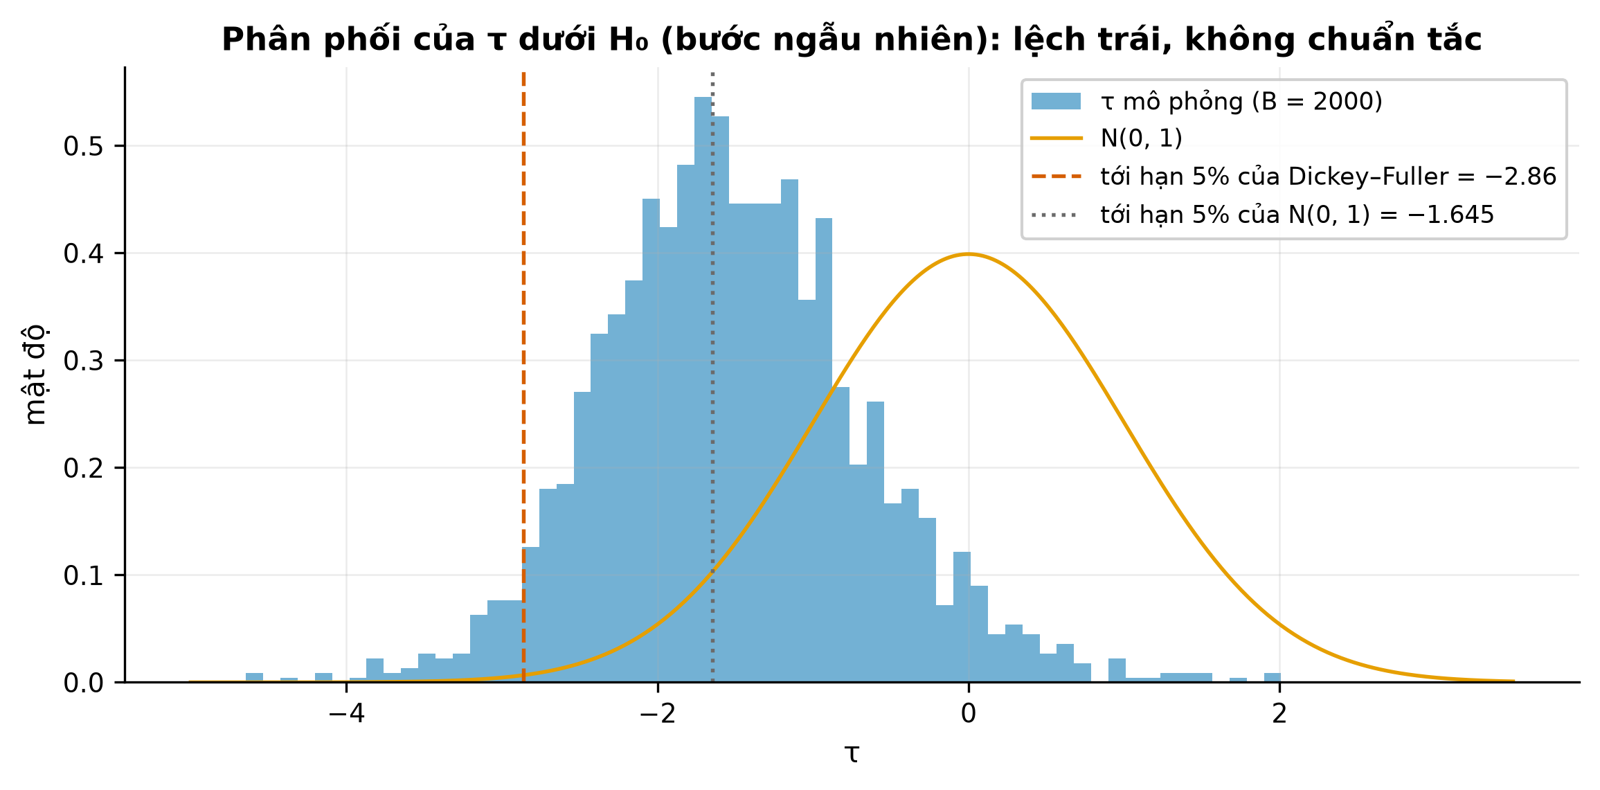

tỷ lệ bác bỏ
mô hình đúng                      n                
AR(1), φ = 0.95                   100         0.138
                                  200         0.327
AR(1), φ = 0.9                    100         0.331
                                  200         0.886
AR(1), φ = 0.8                    100         0.896
                                  200             1
iid N(0,1) + dịch mức 2 ở nửa sau 100             1

In [12]:
display(tab)
display(tab_null)
show_figure(fig_path)
tab_power

### Phân tích và diễn giải

**TODO(nhóm):** viết 2–4 câu diễn giải kết quả ở trên, liên hệ trực tiếp với lý thuyết. Câu hỏi gợi ý:

- Ba bộ rơi vào kết luận nào theo cách đọc ADF + KPSS (I(0), I(1), hay mâu thuẫn)? NI: vì sao cả hai kiểm định có thể cùng bác bỏ (đổi mức quanh 1899)?
- Phân phối của $\tau$ dưới $H_0$ lệch trái thế nào so với $N(0,1)$; dùng −1.645 sẽ bác bỏ nghiệm đơn vị đúng bao nhiêu lần?
- Công suất ADF với $\phi=0.95$, $n=100$ thấp thế nào, và dịch mức tạo bác bỏ hay không bác bỏ sai ra sao (bảng bài giảng: 0.14, 0.32, 0.35, 0.84, 0.84, 0.99, 0.08)?

### Nhận xét

**TODO(nhóm):** kết quả có phù hợp lý thuyết không? Nếu lệch, do đặc điểm nào của dữ liệu?

*Lưu ý:* mô phỏng công suất dùng ADF không độ trễ (Dickey–Fuller), B = 1000 (bài giảng 4000). Các hàng AR(1) khớp bài giảng sát; hàng 'iid + dịch mức' của bài giảng (0.08) KHÔNG tái lập được: với dịch mức 2σ ở nửa sau, ADF vẫn bác bỏ gần như luôn (≈ 1.0) vì chuỗi có tự tương quan ≈ 0.5, nên nhóm cần hỏi giảng viên hoặc xem lại thiết kế mô phỏng trước khi kết luận về tác động của điểm gãy.

## 12.5 Mô hình ARIMA(p, d, q) và độ trôi

*Bộ dữ liệu:* NI, DP (AP: xem 12.10)

### Nội dung lý thuyết

**Định nghĩa 2.** $\phi(B)\nabla^dY_t=c+\theta(B)\varepsilon_t$ với $\phi,\theta$ không nghiệm trong $|z|\le1$ và không nghiệm chung; trung bình của chuỗi sai phân $\mu_W=c/\phi(1)$.
$d=1$: $\mu_W$ là độ trôi, dự báo dài hạn là đường thẳng có hệ số góc $\mu_W$; thiếu độ trôi thì dự báo chân trời dài phẳng. ARIMA(0,1,0) là bước ngẫu nhiên. Trong statsmodels: `trend="t"` thêm độ trôi cho mô hình sai phân.

### Cách triển khai

**[D]** NI: ARIMA(0,1,1) không hằng số. DP: bước ngẫu nhiên có trôi `ARIMA(0,1,0, trend="t")` (so với $\hat\delta,\hat\sigma$ tính tay từ $\nabla y$) và ARIMA(1,1,0) có trôi; báo $\hat\mu_W=\hat c/\hat\phi(1)$,
SE, AIC. Hình: dự báo 100 ngày của DP khi có và không có độ trôi.

### Mã lệnh Python

In [13]:
ni = ARIMA(NI, order=(0, 1, 1), trend="n").fit()
dp_rw = ARIMA(LD, order=(0, 1, 0), trend="t").fit(); dp_rw0 = ARIMA(LD, order=(0, 1, 0), trend="n").fit(); dp_ar = ARIMA(LD, order=(1, 1, 0), trend="t").fit()
d1 = np.diff(LD)
pl = lambda k: PLAB.get(k, k)
models = {"NI: ARIMA(0,1,1), không trôi": ni, "DP: ARIMA(0,1,0) + trôi": dp_rw, "DP: ARIMA(1,1,0) + trôi": dp_ar}
rows, stat_rows = [], []
for name, f in models.items():
    for k, v, se in zip(f.param_names, f.params, f.bse):
        rows.append({"mô hình": name, "tham số": pl(k), "ước lượng": v, "SE": se, "thống kê z": v / se})
    mu_w = 0.0 if f is ni else f.params[0] / (1 - (f.arparams[0] if len(f.arparams) else 0.0))
    stat_rows.append({"mô hình": name, "μ̂_W = ĉ/φ̂(1)": mu_w, "AIC": f.aic, "BIC": f.bic, "số quan sát": int(f.nobs)})
tab = save_table(pd.DataFrame(rows).set_index(["mô hình", "tham số"]), "tab_b12_05_arima_params")
tab_stats = save_table(pd.DataFrame(stat_rows).set_index("mô hình"), "tab_b12_05_fit_stats")
tab_manual = save_table(pd.DataFrame({"tay (từ ∇y)": [d1.mean(), d1.var(ddof=1)], "ARIMA(0,1,0) + trôi": [dp_rw.params[0], sig2(dp_rw)]}, index=["δ̂ (độ trôi)", "σ̂²"]), "tab_b12_05_rw_manual_vs_arima")
h, n_show = 100, 150; fig, ax = plt.subplots(figsize=(8.5, 3.9)); xs_hist = np.arange(len(LD) - n_show + 1, len(LD) + 1); xs_f = np.arange(len(LD) + 1, len(LD) + h + 1)
ax.plot(xs_hist, LD[-n_show:], color="k", lw=1.0, label="log DAX quan sát")
for f, lab, col in ((dp_rw, "dự báo có độ trôi (trend='t')", BLUE), (dp_rw0, "dự báo không có độ trôi (trend='n')", ORANGE)):
    ax.plot(xs_f, f.get_forecast(h).predicted_mean, color=col, lw=1.8, label=lab)
ax.set(title="DP: dự báo 100 ngày giao dịch tiếp theo", xlabel="ngày giao dịch t", ylabel="log DAX"); ax.legend(loc="upper left")
fig_path = save_figure(fig, "fig_b12_05_drift_forecast")
print("AP: mô hình airline SARIMA(0,1,1)(0,1,1)₁₂ ở mục 12.10; NI không có trôi vì trung bình của ∇y ≈ 0 (đổi mức, không xu thế).")

AP: mô hình airline SARIMA(0,1,1)(0,1,1)₁₂ ở mục 12.10; NI không có trôi vì trung bình của ∇y ≈ 0 (đổi mức, không xu thế).


### Kết quả

ước lượng        SE  thống kê z
mô hình                      tham số                                     
NI: ARIMA(0,1,1), không trôi θ              -0.7334   0.07441      -9.857
                             σ²            2.06e+04      2860       7.203
DP: ARIMA(0,1,0) + trôi      c (độ trôi)  0.0006471 0.0002432        2.66
                             σ²            0.000106  1.74e-06        60.9
DP: ARIMA(1,1,0) + trôi      c (độ trôi)   0.000652 0.0002447       2.665
                             φ           -0.0004356   0.01835    -0.02374
                             σ²            0.000106 1.755e-06       60.44

,μ̂_W = ĉ/φ̂(1),AIC,BIC,số quan sát
mô hình,,,,
"NI: ARIMA(0,1,1), không trôi",0,1269,1274,100
"DP: ARIMA(0,1,0) + trôi",0.0006471,-1.173e+04,-1.172e+04,1860
"DP: ARIMA(1,1,0) + trôi",0.0006517,-1.173e+04,-1.171e+04,1860


,tay (từ ∇y),"ARIMA(0,1,0) + trôi"
δ̂ (độ trôi),0.000652,0.0006471
σ̂²,0.0001061,0.000106


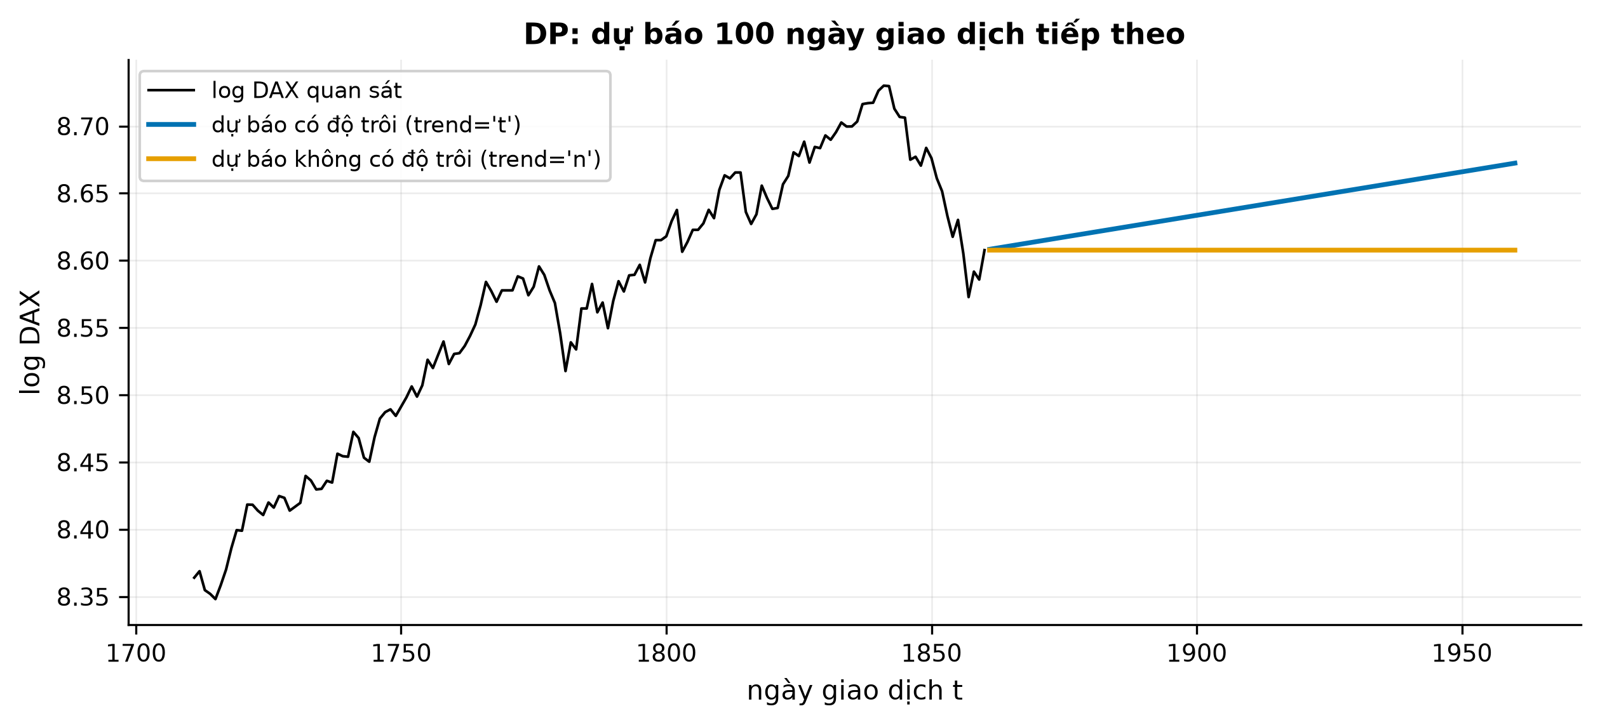

In [14]:
display(tab)
display(tab_stats)
display(tab_manual)
show_figure(fig_path)

### Phân tích và diễn giải

**TODO(nhóm):** viết 2–4 câu diễn giải kết quả ở trên, liên hệ trực tiếp với lý thuyết. Câu hỏi gợi ý:

- $\hat\delta$ của DP có khác 0 so với SE? Dự báo có/không có độ trôi khác nhau thế nào ở chân trời dài?
- ARIMA(1,1,0) có cải thiện đáng kể so với bước ngẫu nhiên có trôi (AIC, ý nghĩa của $\hat\phi$)? $\hat\mu_W=c/\phi(1)$ khác $\hat c$ bao nhiêu?
- NI: $\hat\theta$ và vì sao không đưa độ trôi vào?

### Nhận xét

**TODO(nhóm):** kết quả có phù hợp lý thuyết không? Nếu lệch, do đặc điểm nào của dữ liệu?

## 12.6 Ảnh hưởng vĩnh viễn của cú sốc: trọng số Ψ

*Bộ dữ liệu:* NI, DP (AP: giải thích)

### Nội dung lý thuyết

**Định lý 3(a,b).** Với $d=1$, ảnh hưởng của $\varepsilon_t$ lên $Y_{t+k}$ là $\Psi_k=\sum_{j\le k}\psi_j$ (hệ số của $\Psi(z)=\theta(z)/\{\phi(z)(1-z)^d\}$) và
$\Psi_k\to\theta(1)/\phi(1)$: bằng 1 cho bước ngẫu nhiên, $1+\theta$ cho ARIMA(0,1,1); với $d=0$ ảnh hưởng tắt dần ($\Psi_k=\psi_k\to0$).

### Cách triển khai

**[D]** Từ mô hình đã khớp ở 12.5 tính $\Psi_k$ bằng `Psi_weights_arima` (đệ quy tay) và giới hạn $\theta(1)/\phi(1)$: NI (ARIMA(0,1,1)), DP (bước ngẫu nhiên và ARIMA(1,1,0));
đối chứng $d=0$: AR(1) $\phi=0.6$ (minh họa lý thuyết). AP mùa vụ: cú sốc cũng vĩnh viễn nhưng xem 12.10.

### Mã lệnh Python

In [15]:
ni = ARIMA(NI, order=(0, 1, 1), trend="n").fit(); dp_ar = ARIMA(LD, order=(1, 1, 0), trend="t").fit()
th = ni.maparams[0]; ph = dp_ar.arparams[0]
models = {"NI ARIMA(0,1,1)": ([], [th], 1), "DP bước ngẫu nhiên": ([], [], 1), "DP ARIMA(1,1,0)": ([ph], [], 1), "đối chứng AR(1) φ=0.6, d=0": ([0.6], [], 0)}
ks = [0, 1, 2, 5, 10, 50, 100]; rows = {}; fig, ax = plt.subplots(figsize=(7.8, 3.9))
styles = {"NI ARIMA(0,1,1)": (BLUE, "-", 2.0), "DP bước ngẫu nhiên": (ORANGE, "-", 4.5), "DP ARIMA(1,1,0)": (GREEN, "--", 1.8), "đối chứng AR(1) φ=0.6, d=0": (RED, "-", 2.0)}
for name, (phi, theta, d) in models.items():
    Psi = F.Psi_weights_arima(phi, theta, d, 101); lim = (1 + sum(theta)) / (1 - sum(phi)) if d == 1 else 0.0
    rows[name] = {**{f"Ψ_{k}": Psi[k] for k in ks}, "giới hạn θ(1)/φ(1) (d = 1) hoặc 0": lim}; ax.plot(np.arange(40), Psi[:40], color=styles[name][0], ls=styles[name][1], lw=styles[name][2], label=name)
ax.set(xlabel="k (số kỳ sau cú sốc)", ylabel="Ψₖ", title="Ảnh hưởng của một cú sốc đơn vị lên Yₜ₊ₖ"); ax.legend(loc="center right")
fig_path = save_figure(fig, "fig_b12_06_psi_weights")
tab = save_table(pd.DataFrame(rows).T, "tab_b12_06_psi_weights")
print(f"NI: 1 + θ̂ = {1 + th:.4f} (α của làm trơn mũ, 12.7); DP ARIMA(1,1,0): 1/(1−φ̂) = {1 / (1 - ph):.4f}")

NI: 1 + θ̂ = 0.2666 (α của làm trơn mũ, 12.7); DP ARIMA(1,1,0): 1/(1−φ̂) = 0.9996


### Kết quả

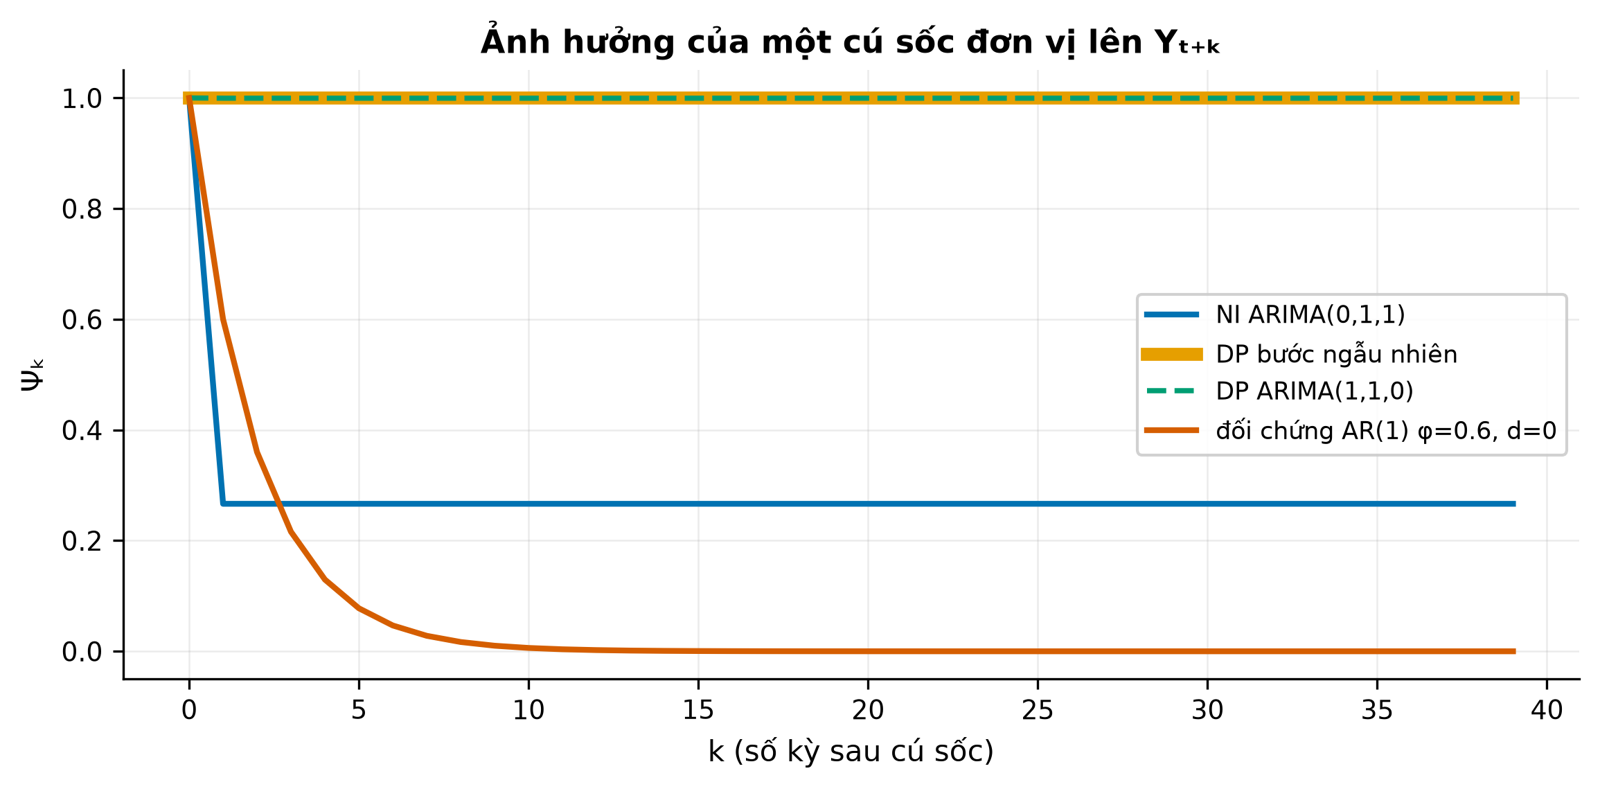

,Ψ_0,Ψ_1,Ψ_2,Ψ_5,Ψ_10,Ψ_50,Ψ_100,giới hạn θ(1)/φ(1) (d = 1) hoặc 0
"NI ARIMA(0,1,1)",1,0.2666,0.2666,0.2666,0.2666,0.2666,0.2666,0.2666
DP bước ngẫu nhiên,1,1,1,1,1,1,1,1
"DP ARIMA(1,1,0)",1,0.9996,0.9996,0.9996,0.9996,0.9996,0.9996,0.9996
"đối chứng AR(1) φ=0.6, d=0",1,0.6,0.36,0.07776,0.006047,8.083e-12,6.533e-23,0


In [16]:
show_figure(fig_path)
tab

### Phân tích và diễn giải

**TODO(nhóm):** viết 2–4 câu diễn giải kết quả ở trên, liên hệ trực tiếp với lý thuyết. Câu hỏi gợi ý:

- $\Psi_k$ hội tụ về giá trị nào cho NI, DP; có khớp $\theta(1)/\phi(1)$ không?
- Diễn giải 'hệ số nhân dài hạn' của NI ($\approx0.27$): nếu năm nay lưu lượng cao hơn dự báo 1 đơn vị, nên điều chỉnh quan điểm về các năm sau bao nhiêu?
- Tại sao $d=0$ thì cú sốc tắt dần còn $d=1$ thì không?

### Nhận xét

**TODO(nhóm):** kết quả có phù hợp lý thuyết không? Nếu lệch, do đặc điểm nào của dữ liệu?

## 12.7 ARIMA(0,1,1) ≡ làm trơn mũ đơn ≡ mô hình mức cục bộ

*Bộ dữ liệu:* NI (chính); DP, AP: giải thích

### Nội dung lý thuyết

**Định lý 3(c).** Nếu $\nabla Y_t=\varepsilon_t+\theta\varepsilon_{t-1}$, $|\theta|<1$, $\alpha=1+\theta$: $\hat Y_{n+h|n}=\alpha Y_n+(1-\alpha)\hat Y_{n|n-1}=\alpha\sum_{j\ge0}(1-\alpha)^jY_{n-j}$ với mọi $h\ge1$.
**Ví dụ 2.2 (mức cục bộ).** $Y_t=\mu_t+\varepsilon_t$, $\mu_t=\mu_{t-1}+\eta_t$: $\nabla Y$ là MA(1); $\sigma_\varepsilon^2=-\theta\sigma^2$, $\sigma_\eta^2=(1+\theta)^2\sigma^2$, $\rho(1)=-1/(q+2)$, $q=\sigma^2_\eta/\sigma^2_\varepsilon$.

### Cách triển khai

**[D]** NI: $\alpha=1+\hat\theta$; đệ quy làm trơn tay (khởi tạo $y_1$) so với dự báo của ARIMA(0,1,1), với `SimpleExpSmoothing` ($\alpha$ cố định) và với $\alpha$ tối ưu; ước lượng
$\sigma^2_\varepsilon,\sigma^2_\eta$ từ $(\hat\theta,\hat\sigma^2)$ và trực tiếp từ `UnobservedComponents('llevel')`. DP chỉ là trường hợp $\theta=0$ ($\alpha=1$); AP có mùa vụ nên không phải mức cục bộ thuần.

### Mã lệnh Python

In [17]:
ni = ARIMA(NI, order=(0, 1, 1), trend="n").fit()
th, s2_ = ni.maparams[0], sig2(ni); alpha = 1 + th
level = F.ses_recursion(NI, alpha); fc_arima = ni.get_forecast(1).predicted_mean[0]
ses_fixed = SimpleExpSmoothing(NI, initialization_method="known", initial_level=NI[0]).fit(smoothing_level=alpha, optimized=False)
ses_opt = SimpleExpSmoothing(NI, initialization_method="estimated").fit()
uc = UnobservedComponents(NI, "llevel").fit(disp=False)
eps_v, eta_v = F.local_level_variances(th, s2_)
tab_fc = save_table(pd.DataFrame({"dự báo 1971": [fc_arima, level[-1], ses_fixed.forecast(1)[0], ses_opt.forecast(1)[0]]},
    index=["ARIMA(0,1,1)", f"đệ quy tay, α = 1+θ̂ = {alpha:.4f}", "SimpleExpSmoothing (α cố định, ℓ₁ = y₁)", f"SimpleExpSmoothing (α̂ = {ses_opt.params['smoothing_level']:.4f} tối ưu)"]), "tab_b12_07_ses_forecasts")
ucp = dict(zip(uc.param_names, uc.params))
tab_var = save_table(pd.DataFrame({"σ²_ε (nhiễu quan sát)": [eps_v, ucp["sigma2.irregular"]], "σ²_η (nhiễu mức)": [eta_v, ucp["sigma2.level"]]},
    index=["từ (θ̂, σ̂²) của ARIMA(0,1,1)", "UnobservedComponents('llevel')"]).assign(**{"q = σ²_η/σ²_ε": lambda d: d["σ²_η (nhiễu mức)"] / d["σ²_ε (nhiễu quan sát)"]}), "tab_b12_07_local_level")
q = eta_v / eps_v; print(f"ρ(1) của ∇Y: θ̂/(1+θ̂²) = {th / (1 + th ** 2):.4f}; −1/(q+2) = {-1 / (q + 2):.4f}")
print(f"tổng trọng số α(1−α)^j (j < 100) = {sum(alpha * (1 - alpha) ** j for j in range(100)):.6f}")

ρ(1) của ∇Y: θ̂/(1+θ̂²) = -0.4769; −1/(q+2) = -0.4769


tổng trọng số α(1−α)^j (j < 100) = 1.000000


### Kết quả

In [18]:
display(tab_fc)
tab_var

,dự báo 1971
"ARIMA(0,1,1)",798.5
"đệ quy tay, α = 1+θ̂ = 0.2666",798.5
"SimpleExpSmoothing (α cố định, ℓ₁ = y₁)",798.5
SimpleExpSmoothing (α̂ = 0.2457 tối ưu),805.3


,σ²_ε (nhiễu quan sát),σ²_η (nhiễu mức),q = σ²_η/σ²_ε
"từ (θ̂, σ̂²) của ARIMA(0,1,1)",1.511e+04,1464,0.09687
UnobservedComponents('llevel'),1.508e+04,1479,0.09808


### Phân tích và diễn giải

**TODO(nhóm):** viết 2–4 câu diễn giải kết quả ở trên, liên hệ trực tiếp với lý thuyết. Câu hỏi gợi ý:

- Bốn cách tính dự báo 1971 có trùng nhau không; sai khác do đâu (khởi tạo ℓ₁, α)?
- $\hat\alpha\approx0.27$ nghĩa là mỗi cú sốc có bao nhiêu phần trở thành vĩnh viễn; tỷ số tín hiệu/nhiễu $q$ nói gì về Nile?
- $\sigma^2_\varepsilon,\sigma^2_\eta$ từ ARIMA và từ mô hình không gian trạng thái có trùng nhau không?

### Nhận xét

**TODO(nhóm):** kết quả có phù hợp lý thuyết không? Nếu lệch, do đặc điểm nào của dữ liệu?

## 12.8 Dự báo h bước tối ưu MSE, phương sai sai số và khoảng dự báo

*Bộ dữ liệu:* NI, AP, DP (cả 3) + mô phỏng độ phủ

### Nội dung lý thuyết

**Định lý 4.** $\hat Y_{n+h|n}=E(Y_{n+h}|\mathcal F_n)$; $e_n(h)=\sum_{j<h}\Psi_j\varepsilon_{n+h-j}$ (MA(h−1)), $\operatorname{Var}e_n(h)=\sigma^2\sum_{j<h}\Psi_j^2$.
Trường hợp riêng: $h\sigma^2$ (ARIMA(0,1,0)); $\sigma^2\{1+(h-1)\alpha^2\}$ (ARIMA(0,1,1), $\alpha=1+\theta$); $\sigma^2(1-\phi^{2h})/(1-\phi^2)\to\gamma(0)$ (AR(1) nhân quả).
Khoảng $(1-a)$: $\hat Y_{n+h|n}\pm z_{1-a/2}\,\sigma(\sum_{j<h}\Psi_j^2)^{1/2}$ chính xác khi tham số đã biết; ước lượng tham số, chọn bậc làm khoảng chỉ xấp xỉ. $d=0$: độ rộng hội tụ $2z\sqrt{\gamma(0)}$; $d=1$ tăng như $\sqrt h$.

### Cách triển khai

**[D]** Phương sai sai số dự báo tính tay (Ψ + công thức đóng) so với `get_forecast().var_pred_mean`: NI ARIMA(0,1,1) ($h\le10$), DP bước ngẫu nhiên có trôi ($h\le250$), AP airline trên thang log ($h\le24$,
Ψ từ tích đa thức SARIMA). Đối chứng $d=0$: AR(1) $\phi=0.8$. **[M]** độ phủ khoảng 95% tại $h=1,5,10$: ARIMA(0,1,1) $\theta=-0.5,\sigma=1,n=100$ (thiết kế bài giảng, $B=2000$) và với $\hat\theta,\hat\sigma$ của NI ($n=100$, $B=1000$);
mỗi lần khớp lại mô hình đúng.

### Mã lệnh Python

In [19]:
ni = ARIMA(NI, order=(0, 1, 1), trend="n").fit(); th, s2_ = ni.maparams[0], sig2(ni); alpha = 1 + th
H = 10; Psi = F.Psi_weights_arima([], [th], 1, H); hh = np.arange(1, H + 1)
var_ni = F.forecast_variance_manual(Psi, s2_, H); var_ni_closed = s2_ * (1 + (hh - 1) * alpha ** 2); var_ni_sm = ni.get_forecast(H).var_pred_mean
dp = ARIMA(LD, order=(0, 1, 0), trend="t").fit(); Hd = 250; hd = np.arange(1, Hd + 1)
var_dp = F.forecast_variance_manual(F.Psi_weights_arima([], [], 1, Hd), sig2(dp), Hd); var_dp_sm = dp.get_forecast(Hd).var_pred_mean
ap = airline(TR); pa = dict(zip(ap.param_names, ap.params))
ar_p, ma_p = F.sarima_polys(theta=[pa["ma.L1"]], Theta=[pa["ma.S.L12"]], d=1, D=1, s=12)
var_ap = F.forecast_variance_manual(F.psi_from_polys(ar_p, ma_p, 24), pa["sigma2"], 24); var_ap_sm = ap.get_forecast(24).var_pred_mean
rel = lambda a, b: float(np.max(np.abs(a / b - 1)))  # noqa: E731
tab = save_table(pd.DataFrame([
    {"bộ": "NI ARIMA(0,1,1)", "h tối đa": H, "SE tay (h=1)": np.sqrt(var_ni[0]), "SE tay (h=tối đa)": np.sqrt(var_ni[-1]), "SE statsmodels (h=tối đa)": np.sqrt(var_ni_sm[-1]),
     "max |tay/statsmodels − 1|": rel(var_ni, var_ni_sm), "max |công thức đóng/Ψ − 1|": rel(var_ni_closed, var_ni)},
    {"bộ": "DP bước ngẫu nhiên + trôi", "h tối đa": Hd, "SE tay (h=1)": np.sqrt(var_dp[0]), "SE tay (h=tối đa)": np.sqrt(var_dp[-1]), "SE statsmodels (h=tối đa)": np.sqrt(var_dp_sm[-1]),
     "max |tay/statsmodels − 1|": rel(var_dp, var_dp_sm), "max |công thức đóng/Ψ − 1|": rel(sig2(dp) * hd, var_dp)},
    {"bộ": "AP airline (log)", "h tối đa": 24, "SE tay (h=1)": np.sqrt(var_ap[0]), "SE tay (h=tối đa)": np.sqrt(var_ap[-1]), "SE statsmodels (h=tối đa)": np.sqrt(var_ap_sm[-1]),
     "max |tay/statsmodels − 1|": rel(var_ap, var_ap_sm), "max |công thức đóng/Ψ − 1|": np.nan}]).set_index("bộ"), "tab_b12_08_forecast_variance")
g = np.arange(1, 25); fig, ax = plt.subplots(figsize=(7.8, 3.9))
ax.plot(g, np.sqrt(g), color=RED, lw=1.8, label="bước ngẫu nhiên ARIMA(0,1,0): √h"); ax.plot(g, np.sqrt(1 + (g - 1) * 0.5 ** 2), color=BLUE, lw=1.8, label="ARIMA(0,1,1), α = 0.5")
ax.plot(g, np.sqrt((1 - 0.8 ** (2 * g)) / (1 - 0.8 ** 2)), color=GREEN, lw=1.8, label="AR(1), φ = 0.8 (d = 0)"); ax.axhline(np.sqrt(1 / (1 - 0.64)), color=GREY, ls=":", label="√γ(0) của AR(1)")
ax.set(xlabel="chân trời h", ylabel="SE của eₙ(h) với σ = 1", title="Độ rộng khoảng dự báo: d = 0 hội tụ, d = 1 tăng không giới hạn"); ax.legend(loc="upper left")
fig_path = save_figure(fig, "fig_b12_08_se_growth")
fc_ni = ni.get_forecast(20); ci_ni = fc_ni.conf_int(); yrs = DATA["NI"].year.to_numpy(); fyr = np.arange(yrs[-1] + 1, yrs[-1] + 21)
fig, ax = plt.subplots(figsize=(8.5, 3.9))
ax.plot(yrs, NI, color="k", lw=1.0, label="lưu lượng quan sát"); ax.plot(fyr, fc_ni.predicted_mean, color=BLUE, lw=2, label="dự báo ARIMA(0,1,1)")
ax.fill_between(fyr, ci_ni[:, 0], ci_ni[:, 1], color=BLUE, alpha=0.18, label="khoảng dự báo 95%")
ax.set(xlabel="năm", ylabel="lưu lượng (10⁸ m³)", title="NI: dự báo 20 năm (phẳng vì d = 1, không trôi; khoảng mở rộng vì Ψⱼ không tắt dần)"); ax.legend(loc="lower left")
fig_path_ni = save_figure(fig, "fig_b12_08_ni_forecast")

In [20]:
def coverage_sim(theta, sigma, n, B, rng, hs=(1, 5, 10)):
    hits = dict.fromkeys(hs, 0)
    for _ in range(B):
        y = np.cumsum(S.simulate_arma([], [theta], n + 10, rng, sigma=sigma))
        ci = ARIMA(y[:n], order=(0, 1, 1), trend="n").fit().get_forecast(10).conf_int(alpha=0.05)
        for h in hs: hits[h] += ci[h - 1, 0] <= y[n + h - 1] <= ci[h - 1, 1]
    return {f"h = {h}": hits[h] / B for h in hs}, np.sqrt(0.95 * 0.05 / B)
cov1, mc1 = coverage_sim(-0.5, 1.0, 100, 2000, S.child_rng(12, 8))
cov2, mc2 = coverage_sim(th, np.sqrt(s2_), 100, 1000, S.child_rng(12, 81))
tab_cov = save_table(pd.DataFrame([{"thiết kế": "θ = −0.5, σ = 1, n = 100, B = 2000", **cov1, "MCSE ≈": mc1},
                                   {"thiết kế": f"θ = {th:.3f}, σ = {np.sqrt(s2_):.1f} (NI), n = 100, B = 1000", **cov2, "MCSE ≈": mc2}]).set_index("thiết kế"), "tab_b12_08_coverage")

### Kết quả

,h tối đa,SE tay (h=1),SE tay (h=tối đa),SE statsmodels (h=tối đa),max |tay/statsmodels − 1|,max |công thức đóng/Ψ − 1|
bộ,,,,,,
"NI ARIMA(0,1,1)",10,143.5,183.8,183.8,2.909e-14,2.22e-16
DP bước ngẫu nhiên + trôi,250,0.0103,0.1628,0.1628,2.887e-15,0
AP airline (log),24,0.03745,0.155,0.155,1.008e-05,NaN


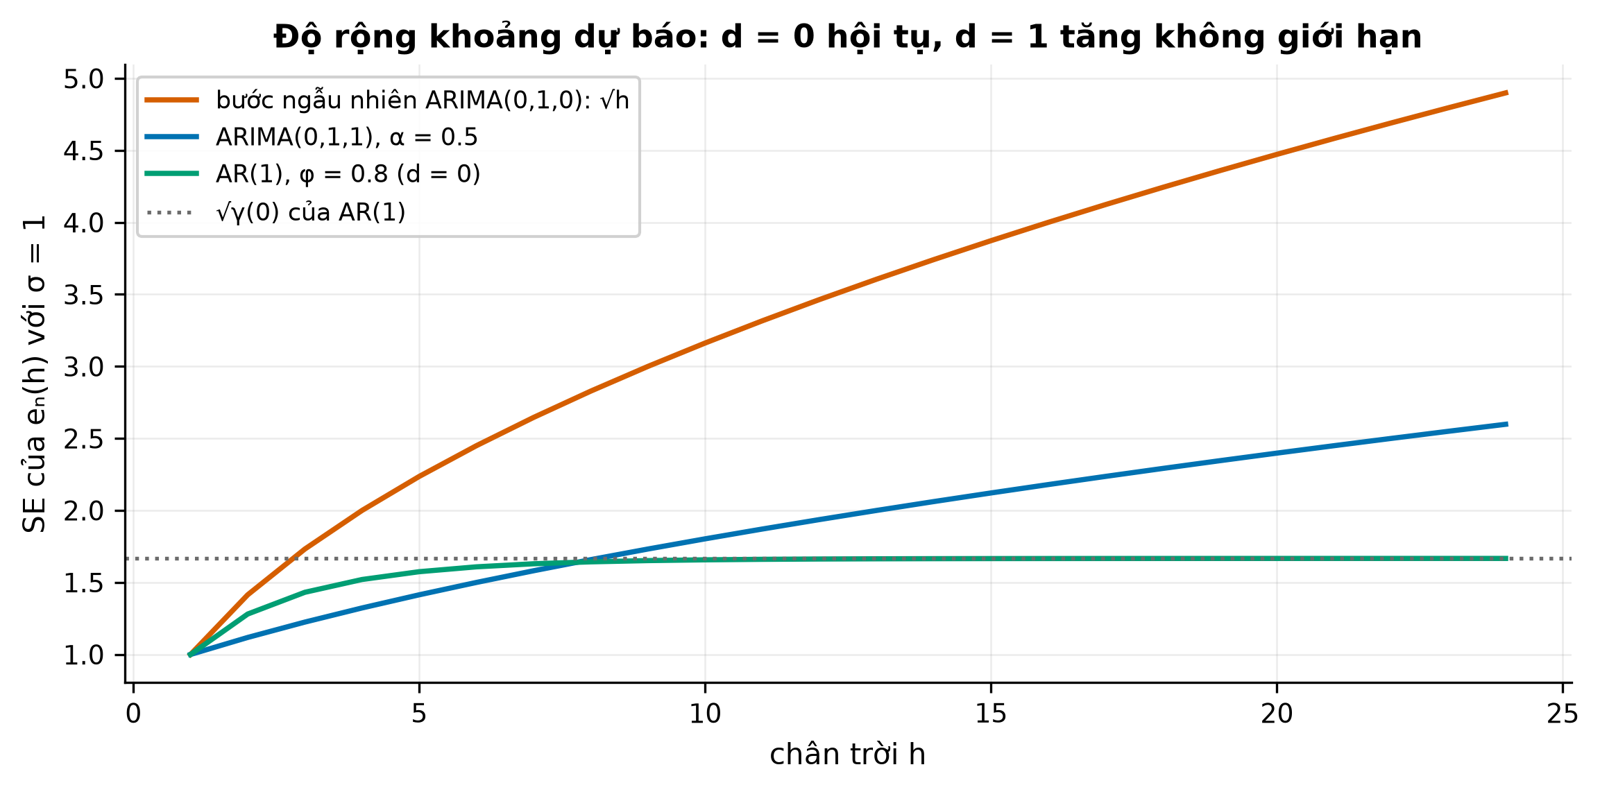

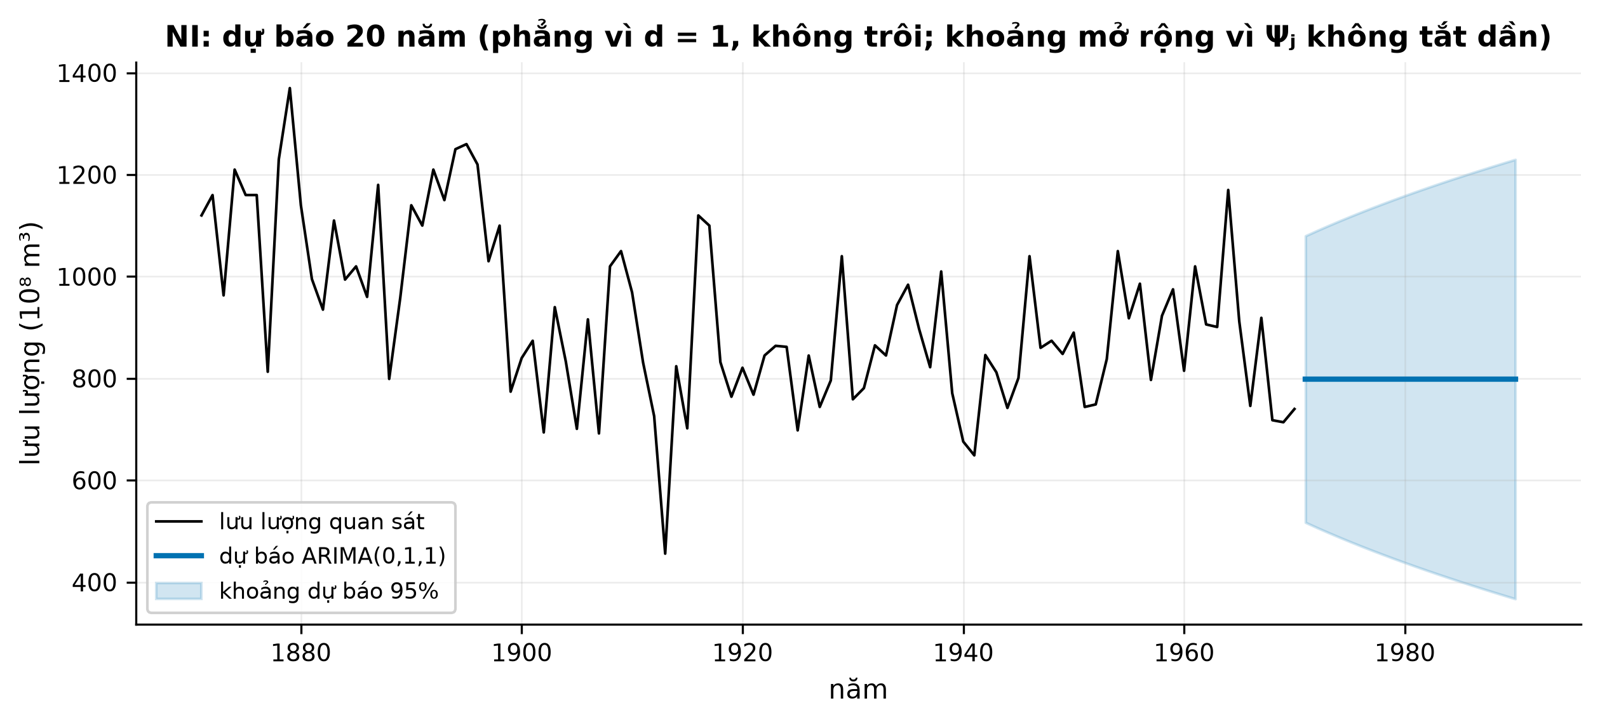

,h = 1,h = 5,h = 10,MCSE ≈
thiết kế,,,,
"θ = −0.5, σ = 1, n = 100, B = 2000",0.9375,0.944,0.9465,0.004873
"θ = -0.733, σ = 143.5 (NI), n = 100, B = 1000",0.934,0.943,0.944,0.006892


In [21]:
display(tab)
show_figure(fig_path)
show_figure(fig_path_ni)
tab_cov

### Phân tích và diễn giải

**TODO(nhóm):** viết 2–4 câu diễn giải kết quả ở trên, liên hệ trực tiếp với lý thuyết. Câu hỏi gợi ý:

- Công thức tay trùng `var_pred_mean` đến mức nào ở ba bộ? Chênh lệch nhỏ còn lại đến từ đâu (khởi tạo Kalman, hữu hạn mẫu)?
- SE của NI tăng thế nào khi $h$ tăng so với bước ngẫu nhiên ($\alpha\sqrt h$ vs $\sqrt h$)? DP: khoảng ở $h=250$ rộng thế nào?
- Độ phủ mô phỏng có đạt 95% (xét MCSE)? Ba điều công thức khoảng dự báo bỏ qua là gì, và đã thấy ảnh hưởng nào ở đây?

### Nhận xét

**TODO(nhóm):** kết quả có phù hợp lý thuyết không? Nếu lệch, do đặc điểm nào của dữ liệu?

## 12.9 Dự báo trên thang log: trung vị, trung bình, khoảng chuyển đổi

*Bộ dữ liệu:* AP, DP (NI: không biến đổi)

### Nội dung lý thuyết

**Mệnh đề 2.** Nếu phân phối dự báo của $\log Y_{n+h}$ là $N(m,s^2)$: (a) khoảng $(e^L,e^U)$ là khoảng $(1-a)$ chính xác cho $Y_{n+h}$; (b) $e^m$ là **trung vị**, còn $E(Y_{n+h}|\mathcal F_n)=e^{m+s^2/2}>e^m$ là **trung bình**;
(c) báo cáo trung vị nếu đánh giá bằng sai số tuyệt đối, trung bình nếu bằng sai số bình phương hoặc khi cần cộng gộp. Hệ số $e^{s^2/2}$: $s=0.04$ → 0.08%, $s=0.3$ → 4.6%.

### Cách triển khai

**[D]** AP: airline (huấn luyện 120 tháng) dự báo 24 tháng 1959–1960: trung vị, trung bình, khoảng 95%, so với giá trị thực (đếm số điểm nằm trong khoảng). DP: bước ngẫu nhiên có trôi với $\hat\delta,\hat\sigma$ từ 1859
suất sinh lợi log, dự báo giá DAX sau 1, 20, 250 ngày giao dịch từ giá cuối 5473.72: trung vị, trung bình, khoảng bất đối xứng.

### Mã lệnh Python

In [22]:
f = airline(TR); g = f.get_forecast(24); m, s = g.predicted_mean, np.sqrt(g.var_pred_mean); bt = F.back_transform_log(m, s); act = AP[120:]
sel = [0, 11, 23]
tab_ap = pd.DataFrame({"tháng": [DATA["AP"].month.iloc[120 + i] for i in sel], "s (thang log)": s[sel], "trung vị = exp(m)": bt["median"][sel], "trung bình = exp(m + s²/2)": bt["mean"][sel],
                       "cận dưới 95%": bt["lower"][sel], "cận trên 95%": bt["upper"][sel], "thực tế": act[sel], "exp(s²/2) − 1 (%)": 100 * (np.exp(s[sel] ** 2 / 2) - 1)}).set_index("tháng")
inside = int(np.sum((act >= bt["lower"]) & (act <= bt["upper"])))
tab_ap = save_table(tab_ap, "tab_b12_09_ap_backtransform")
yrs_all = 1949 + np.arange(144) / 12; fig, ax = plt.subplots(figsize=(8.5, 3.9))
ax.plot(yrs_all[:120], AP[:120], color="k", lw=1.0, label="huấn luyện (1949–1958)"); ax.plot(yrs_all[120:], act, color=GREEN, lw=1.5, marker="o", ms=3, label="thực tế 1959–1960")
ax.plot(yrs_all[120:], bt["median"], color=BLUE, lw=2, label="dự báo airline (trung vị)"); ax.fill_between(yrs_all[120:], bt["lower"], bt["upper"], color=BLUE, alpha=0.18, label="khoảng dự báo 95%")
ax.set(xlabel="năm", ylabel="số hành khách (nghìn người)", title="AP: dự báo mô hình airline 24 tháng trên thang gốc"); ax.legend(loc="upper left")
fig_path = save_figure(fig, "fig_b12_09_ap_forecast")
r = np.diff(LD); delta, sigma = r.mean(), r.std(ddof=1); hs = np.array([1, 20, 250])
bt_dp = F.back_transform_log(LD[-1] + delta * hs, sigma * np.sqrt(hs))
tab_dp = pd.DataFrame({"s = σ̂√h": sigma * np.sqrt(hs), "trung vị": bt_dp["median"], "trung bình": bt_dp["mean"], "cận dưới 95%": bt_dp["lower"], "cận trên 95%": bt_dp["upper"]}, index=pd.Index(hs, name="h (ngày)"))
tab_dp["trên − trung vị"] = tab_dp["cận trên 95%"] - tab_dp["trung vị"]; tab_dp["trung vị − dưới"] = tab_dp["trung vị"] - tab_dp["cận dưới 95%"]
tab_dp = save_table(tab_dp, "tab_b12_09_dp_forecast")
print(f"AP: {inside}/24 giá trị thực nằm trong khoảng 95%; DP: δ̂ = {delta:.6f}, σ̂ = {sigma:.6f}, giá cuối = {DAX[-1]:.2f}")
print("NI: không biến đổi log nên mục này không áp dụng (mức nước/lưu lượng dự báo trực tiếp trên thang gốc).")

AP: 24/24 giá trị thực nằm trong khoảng 95%; DP: δ̂ = 0.000652, σ̂ = 0.010301, giá cuối = 5473.72
NI: không biến đổi log nên mục này không áp dụng (mức nước/lưu lượng dự báo trực tiếp trên thang gốc).


### Kết quả

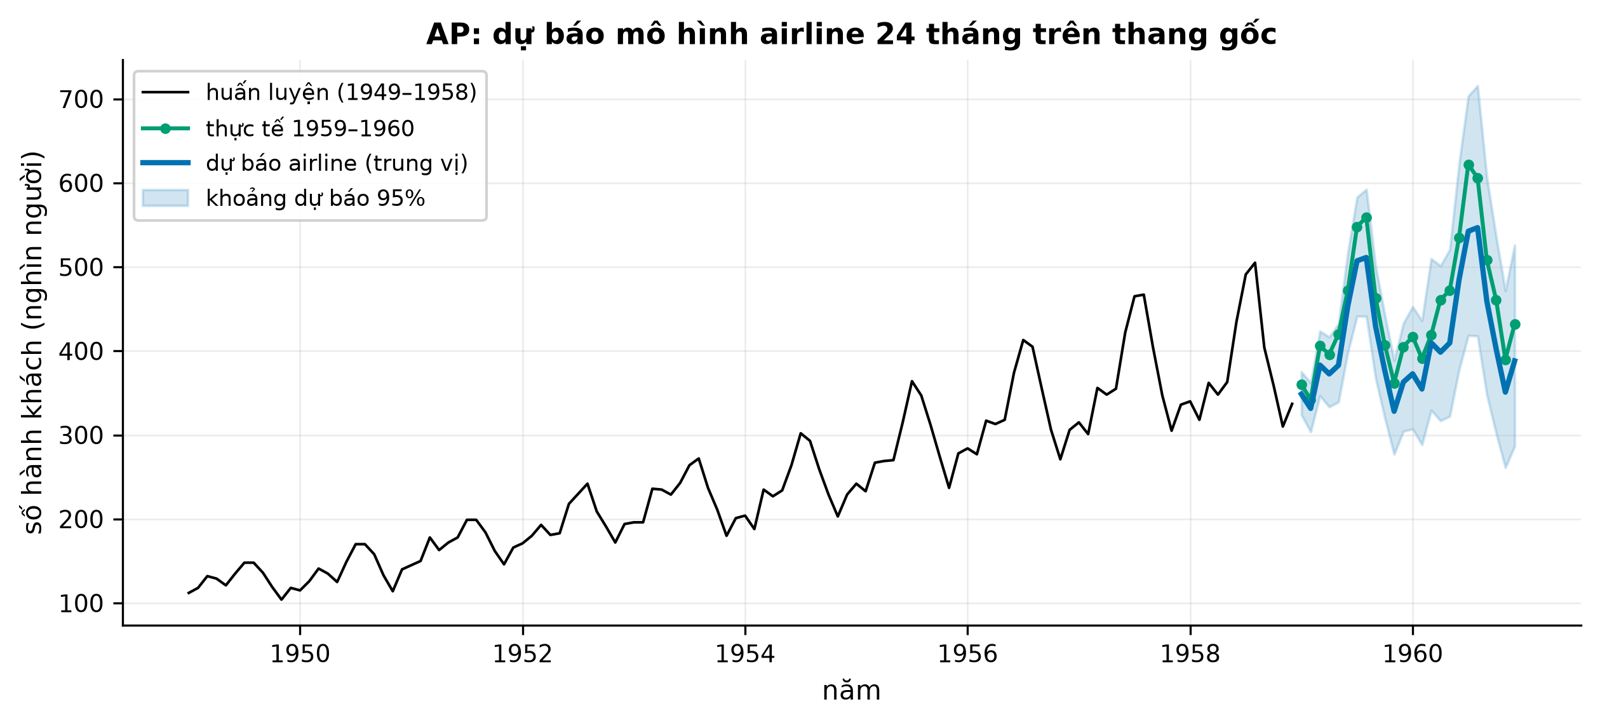

,s (thang log),trung vị = exp(m),trung bình = exp(m + s²/2),cận dưới 95%,cận trên 95%,thực tế,exp(s²/2) − 1 (%)
tháng,,,,,,,
1959-01,0.03745,348.6,348.8,323.9,375.1,360,0.07014
1959-12,0.08984,362.9,364.4,304.4,432.8,405,0.4043
1960-12,0.155,388.2,392.8,286.5,525.9,432,1.208


,s = σ̂√h,trung vị,trung bình,cận dưới 95%,cận trên 95%,trên − trung vị,trung vị − dưới
h (ngày),,,,,,,
1,0.0103,5477,5478,5368,5589,111.7,109.5
20,0.04607,5546,5551,5067,6070,524,478.8
250,0.1629,6443,6529,4682,8866,2423,1761


In [23]:
show_figure(fig_path)
display(tab_ap)
tab_dp

### Phân tích và diễn giải

**TODO(nhóm):** viết 2–4 câu diễn giải kết quả ở trên, liên hệ trực tiếp với lý thuyết. Câu hỏi gợi ý:

- Trung bình và trung vị khác nhau bao nhiêu % ở $h=1$ và $h=24$ (AP)? Bạn sẽ báo cáo đại lượng nào cho quyết định tồn kho và vì sao?
- Khoảng 95% của DP ở $h=250$ bất đối xứng thế nào quanh trung vị, và vì sao ($e^x$ lồi)?
- Bao nhiêu trong 24 giá trị thực của AP nằm trong khoảng? Dự báo điểm có thiên lệch (thấp/cao) không?

### Nhận xét

**TODO(nhóm):** kết quả có phù hợp lý thuyết không? Nếu lệch, do đặc điểm nào của dữ liệu?

## 12.10 Sai phân mùa vụ, SARIMA và mô hình airline

*Bộ dữ liệu:* AP

### Nội dung lý thuyết

**Định nghĩa 4, Định lý 5.** $\nabla_s=1-B^s=(1-B)(1+B+\dots+B^{s-1})$ loại bỏ mẫu mùa vụ cố định và xu thế tuyến tính. SARIMA$(p,d,q)(P,D,Q)_s$: $\Phi(B^s)\phi(B)\nabla^d\nabla_s^DY_t=c+\Theta(B^s)\theta(B)\varepsilon_t$.
Mô hình airline $\nabla\nabla_sY_t=(1+\theta B)(1+\Theta B^s)\varepsilon_t$ là MA($s+1$): $\rho(1)=\frac{\theta}{1+\theta^2}$, $\rho(s)=\frac{\Theta}{1+\Theta^2}$, $\rho(s\pm1)=\rho(1)\rho(s)$, mọi độ trễ khác bằng 0;
khả nghịch ⇔ $|\theta|,|\Theta|<1$. Dự báo dài hạn $a+bh+m_h$ ($m_{h+s}=m_h$, $\sum m_j=0$). $\nabla\nabla_{12}$ mất 13 quan sát.

### Cách triển khai

**[D]** AP huấn luyện 120 tháng: độ lệch chuẩn của $\mathrm{tr},\nabla\mathrm{tr},\nabla_{12}\mathrm{tr},\nabla\nabla_{12}\mathrm{tr}$ (log); ACF của $\nabla\nabla_{12}$ log (dải $\pm1.96/\sqrt{131}$) tại độ trễ 1, 11, 12, 13 so với
giá trị lý thuyết tính từ $(\hat\theta,\hat\Theta)$ (công thức đóng và ACF của đa thức MA(13)). Khớp airline và dự báo 24 tháng. Đối chiếu ba cách mô hình hóa mùa vụ (Ví dụ 4.2): airline, 11 biến giả mùa vụ và $K$ cặp hạng Fourier
(sai số ARIMA(0,1,1)) theo AIC và RMSE trên tập kiểm định 1959–1960.

### Mã lệnh Python

In [24]:
d1, d12 = np.diff(TR), TR[12:] - TR[:-12]; dd = np.diff(d12)
tab_sd = save_table(pd.DataFrame({"n": [len(TR), len(d1), len(d12), len(dd)], "sd": [TR.std(ddof=1), d1.std(ddof=1), d12.std(ddof=1), dd.std(ddof=1)]},
                                 index=["tr = log y", "∇tr", "∇₁₂tr", "∇∇₁₂tr"]), "tab_b12_10_sd")
fit = airline(TR); par = dict(zip(fit.param_names, fit.params)); th_, Th_ = par["ma.L1"], par["ma.S.L12"]
r_hat = A.sample_acf(dd, 25)
ma_coef = np.polymul([1, th_], np.r_[1.0, np.zeros(11), Th_])[1:]       # (1 + θz)(1 + Θz¹²) → θ_1..θ_13
r_ma = R.theoretical_acf([], ma_coef, 25, terms=60)
r1, r12 = th_ / (1 + th_ ** 2), Th_ / (1 + Th_ ** 2)
closed = {1: r1, 11: r1 * r12, 12: r12, 13: r1 * r12}
tab_acf = save_table(pd.DataFrame({"ρ̂(h) của ∇∇₁₂": [r_hat[h] for h in closed], "ρ(h) công thức đóng": list(closed.values()),
                                   "ρ(h) từ MA(13)": [r_ma[h] for h in closed]}, index=pd.Index(list(closed), name="h")), "tab_b12_10_airline_acf")
others = [h for h in range(1, 26) if h not in closed]
print(f"θ̂ = {th_:.4f}, Θ̂ = {Th_:.4f}, σ̂² = {par['sigma2']:.5f}, AIC = {fit.aic:.1f}; dải ±1.96/√{len(dd)} = {1.96 / np.sqrt(len(dd)):.3f}; "
      f"max |ρ(h)| lý thuyết ở các độ trễ còn lại (h ≤ 25) = {np.abs(r_ma[others]).max():.2e}")
fig, ax = plt.subplots(figsize=(9.5, 4.0)); acf_bars(ax, r_hat, len(dd), "AP: ACF của ∇∇₁₂ log y và ACF lý thuyết của mô hình airline")
overlay_theory(ax, range(1, 26), r_ma[1:], "ACF lý thuyết của airline (θ̂, Θ̂)")
fig_path = save_figure(fig, "fig_b12_10_airline_acf")

θ̂ = -0.3425, Θ̂ = -0.5406, σ̂² = 0.00140, AIC = -389.0; dải ±1.96/√107 = 0.189; max |ρ(h)| lý thuyết ở các độ trễ còn lại (h ≤ 25) = 0.00e+00


In [25]:
t_all = np.arange(144); month = np.eye(12)[t_all % 12][:, 1:]
fourier = lambda K: np.column_stack([fn(2 * np.pi * k * t_all / 12) for k in range(1, K + 1) for fn in (np.sin, np.cos)])
rows = [{"mô hình": "airline", "k": len(fit.params), "n dòng": 120, "AIC": fit.aic, "RMSE giữ lại": E.rmse(AP[120:], np.exp(fit.get_forecast(24).predicted_mean))}]
for name, X in (("11 biến giả + ∇ + MA(1)", month), ("Fourier K = 2", fourier(2)), ("Fourier K = 3", fourier(3)), ("Fourier K = 4", fourier(4))):
    try:
        mdl = SARIMAX(TR, exog=X[:120], order=(0, 1, 1), trend="n").fit(disp=0)
        fc = np.exp(mdl.get_forecast(24, exog=X[120:]).predicted_mean)
        rows.append({"mô hình": name, "k": len(mdl.params), "n dòng": 120, "AIC": mdl.aic, "RMSE giữ lại": E.rmse(AP[120:], fc)})
    except Exception as exc:  # báo lỗi rõ thay vì bỏ qua im lặng
        rows.append({"mô hình": name, "k": np.nan, "n dòng": np.nan, "AIC": np.nan, "RMSE giữ lại": np.nan}); print("lỗi:", name, exc)
tab_models = save_table(pd.DataFrame(rows).set_index("mô hình"), "tab_b12_10_seasonality_models")

### Kết quả

,n,sd
tr = log y,120,0.3917
∇tr,119,0.1058
∇₁₂tr,108,0.06598
∇∇₁₂tr,107,0.04619


,ρ̂(h) của ∇∇₁₂,ρ(h) công thức đóng,ρ(h) từ MA(13)
h,,,
1,-0.328,-0.3066,-0.3066
11,0.07618,0.1282,0.1282
12,-0.4058,-0.4183,-0.4183
13,0.1824,0.1282,0.1282


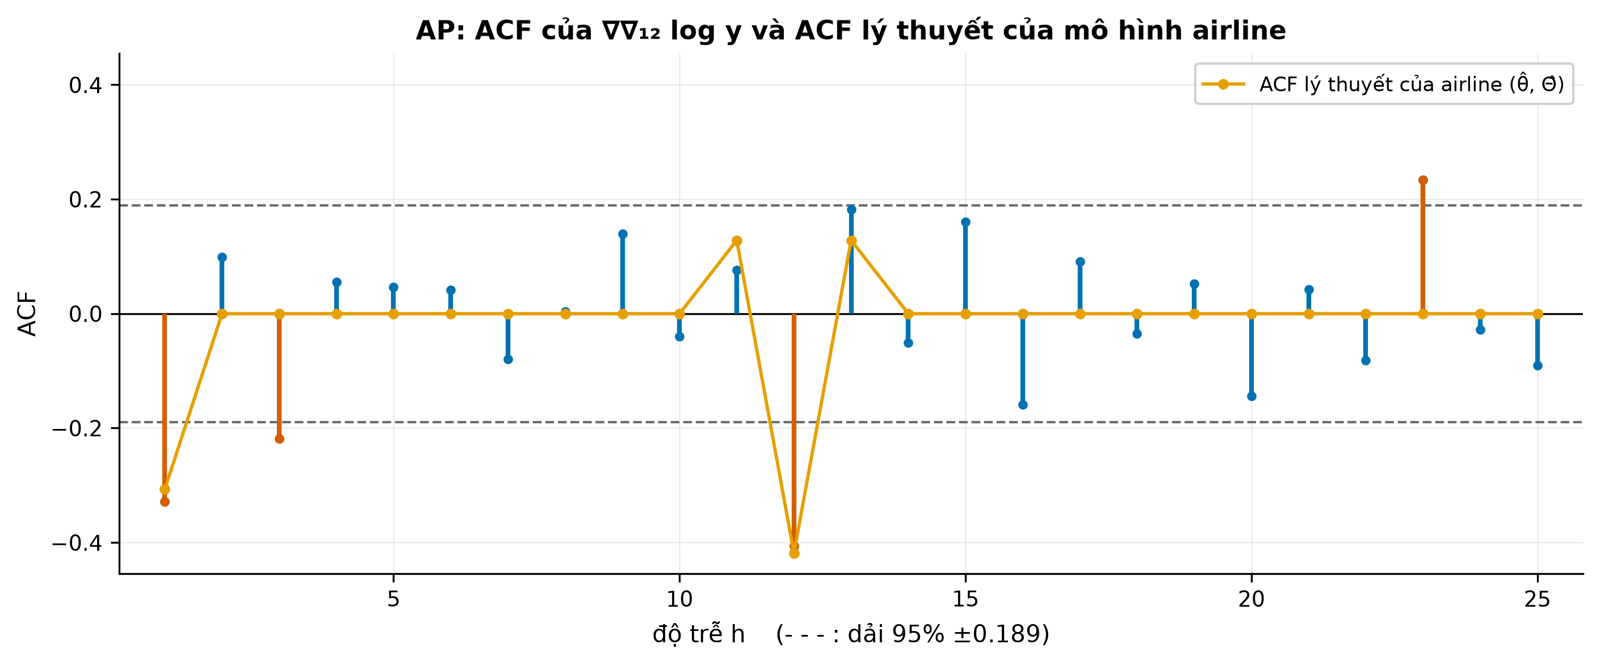

,k,n dòng,AIC,RMSE giữ lại
mô hình,,,,
airline,3,120,-389,43.18
11 biến giả + ∇ + MA(1),13,120,-424.3,85.52
Fourier K = 2,6,120,-311.7,74.81
Fourier K = 3,8,120,-330,77.93
Fourier K = 4,10,120,-384.6,82


In [26]:
display(tab_sd)
display(tab_acf)
show_figure(fig_path)
tab_models

### Phân tích và diễn giải

**TODO(nhóm):** viết 2–4 câu diễn giải kết quả ở trên, liên hệ trực tiếp với lý thuyết. Câu hỏi gợi ý:

- Sai phân nào làm độ lệch chuẩn giảm nhiều nhất, và $\nabla\nabla_{12}$ có dấu hiệu sai phân quá mức không?
- ACF của $\nabla\nabla_{12}$ chỉ có ý nghĩa ở các độ trễ 1, 11–13 không? Giá trị mẫu so với $\rho(1),\rho(12),\rho(11)=\rho(13)=\rho(1)\rho(12)$ lý thuyết?
- So sánh ba cách mô hình hóa mùa vụ: AIC của các mô hình có cùng $d,D$, cùng số dòng không (cảnh báo Bài tập 7(4) và bài giảng)? Xếp hạng theo RMSE giữ lại khác xếp hạng theo AIC không?

### Nhận xét

**TODO(nhóm):** kết quả có phù hợp lý thuyết không? Nếu lệch, do đặc điểm nào của dữ liệu?

*Lưu ý:* Ví dụ 4.2 của bài giảng sai phân hóa trước (n = 107/119 dòng) nên AIC không so được trực tiếp với bảng ở đây; so thứ hạng và xu hướng thay vì số tuyệt đối.

## 12.11 Mốc chuẩn và thước đo độ chính xác

*Bộ dữ liệu:* NI, AP, DP (cả 3)

### Nội dung lý thuyết

**Định nghĩa 5.** Mốc chuẩn: trung bình $\bar y$; naive $y_n$; naive mùa vụ $y_{n+h-s(k+1)}$ ($k=\lfloor(h-1)/s\rfloor$); trôi $y_n+h(y_n-y_1)/(n-1)$. MAE, RMSE, MAPE $=\frac{100}m\sum|e_i/y_{n+i}|$,
MASE $=$ MAE$/Q$, $Q=\frac1{n-s}\sum_{t>s}|y_t-y_{t-s}|$ (MAE của naive mùa vụ một bước trong mẫu huấn luyện). MASE bất biến thang đo; MAPE bất đối xứng (Định lý 6(b,c)). Một con số không kèm chân trời, mốc chuẩn, thang đo thì không phải kết quả.

### Cách triển khai

**[D]** AP: tập kiểm định 24 tháng (1959–60), thang gốc: airline, naive mùa vụ, trôi, naive, trung bình. DP: huấn luyện 1500 ngày, kiểm định 360 ngày: (i) một bước theo log (%, RMSE/MAE) cho naive, trôi, ARIMA(1,1,0)
(tham số cố định từ mẫu huấn luyện, trạng thái cập nhật), (ii) dự báo đa bước từ gốc cố định 1500 trên thang giá. NI (bài giảng không chia sẵn tập kiểm định): **lựa chọn của nhóm** — huấn luyện 80 năm đầu (1871–1950), kiểm định 20 năm cuối, dự báo từ gốc cố định.

### Mã lệnh Python

In [27]:
acc = lambda a, f, tr, s=1: {"RMSE": E.rmse(a, f), "MAE": E.mae(a, f), "MAPE (%)": E.mape(a, f), "MASE": E.mase(a, f, tr, s)}
# AP
tr_ap, te_ap = AP[:120], AP[120:]
air = airline(np.log(tr_ap)); f_air = np.exp(air.get_forecast(24).predicted_mean)
fc_ap = {"airline": f_air, "naive mùa vụ": F.forecast_seasonal_naive(tr_ap, 24, 12), "trôi": F.forecast_drift(tr_ap, 24),
         "naive": F.forecast_naive(tr_ap, 24), "trung bình": F.forecast_mean(tr_ap, 24)}
tab_ap = save_table(pd.DataFrame({k: acc(te_ap, f, tr_ap, 12) for k, f in fc_ap.items()}).T, "tab_b12_11_ap_benchmarks")
# NI
tr_ni, te_ni = NI[:80], NI[80:]
ni_fit = ARIMA(tr_ni, order=(0, 1, 1), trend="n").fit()
fc_ni = {"ARIMA(0,1,1)": ni_fit.forecast(20), "naive": F.forecast_naive(tr_ni, 20), "trôi": F.forecast_drift(tr_ni, 20), "trung bình": F.forecast_mean(tr_ni, 20)}
tab_ni = save_table(pd.DataFrame({k: acc(te_ni, f, tr_ni, 1) for k, f in fc_ni.items()}).T, "tab_b12_11_ni_benchmarks")

In [28]:
# DP: (i) một bước theo log, đơn vị % ; (ii) đa bước từ gốc cố định, thang giá
tr_ld, te_ld = LD[:DP_TRAIN_N], LD[DP_TRAIN_N:]; prev = LD[DP_TRAIN_N - 1:-1]; delta = (tr_ld[-1] - tr_ld[0]) / (DP_TRAIN_N - 1)
ar110 = ARIMA(tr_ld, order=(1, 1, 0), trend="n").fit()
one = {"naive": prev, "trôi": prev + delta, "ARIMA(1,1,0)": ar110.extend(te_ld).fittedvalues}
tab_dp1 = save_table(pd.DataFrame({k: {"RMSE (%)": 100 * E.rmse(te_ld, f), "MAE (%)": 100 * E.mae(te_ld, f)} for k, f in one.items()}).T, "tab_b12_11_dp_one_step")
H = len(te_ld); price_tr, price_te = DAX[:DP_TRAIN_N], DAX[DP_TRAIN_N:]
multi = {"naive": F.forecast_naive(price_tr, H), "trôi": F.forecast_drift(price_tr, H), "trung bình": F.forecast_mean(price_tr, H),
         "ARIMA(1,1,0) (trung vị)": np.exp(ar110.get_forecast(H).predicted_mean)}
tab_dp360 = save_table(pd.DataFrame({k: acc(price_te, f, price_tr, 1) for k, f in multi.items()}).T, "tab_b12_11_dp_multistep")

### Kết quả

In [29]:
display(tab_ap)
display(tab_ni)
display(tab_dp1)
tab_dp360

,RMSE,MAE,MAPE (%),MASE
airline,43.18,39.44,8.515,1.38
naive mùa vụ,76.99,71.25,15.52,2.494
trôi,115.7,91.62,18.41,3.206
naive,137.3,115.2,23.58,4.033
trung bình,219.4,206.3,44.23,7.221


,RMSE,MAE,MAPE (%),MASE
"ARIMA(0,1,1)",122.8,104.3,11.91,0.7777
naive,123.1,102,11.96,0.7604
trôi,122.3,104.6,11.81,0.7799
trung bình,133.3,108,13.16,0.8056


,RMSE (%),MAE (%)
naive,1.439,1.094
trôi,1.435,1.092
"ARIMA(1,1,0)",1.439,1.094


,RMSE,MAE,MAPE (%),MASE
naive,1333,1085,22.01,80.83
trôi,1094,872.3,17.58,64.99
trung bình,2546,2422,52.65,180.5
"ARIMA(1,1,0) (trung vị)",1333,1085,22.01,80.83


### Phân tích và diễn giải

**TODO(nhóm):** viết 2–4 câu diễn giải kết quả ở trên, liên hệ trực tiếp với lý thuyết. Câu hỏi gợi ý:

- AP: airline vượt các mốc chuẩn bao nhiêu lần theo RMSE và MASE (< 1 nghĩa là gì)? MAPE bất đối xứng ảnh hưởng thứ hạng thế nào?
- DP: ba phương pháp một bước gần như bằng nhau (RMSE ≈ 1.44%) — điều đó cho biết gì về khả năng dự báo của log giá DAX?
- NI: ARIMA(0,1,1) có hơn naive trên 20 năm cuối không? Tập kiểm định nhỏ và chọn mô hình trên cùng dữ liệu làm lạc quan thế nào (Bài tập 9(4))?

### Nhận xét

**TODO(nhóm):** kết quả có phù hợp lý thuyết không? Nếu lệch, do đặc điểm nào của dữ liệu?

## 12.12 Thẩm định trên gốc cuốn chiếu và vai trò của bước chọn mô hình

*Bộ dữ liệu:* NI, AP, DP (cả 3)

### Nội dung lý thuyết

**Định nghĩa 5(c).** Với các gốc $t=t_0,\dots,n-h$ khớp lại mô hình trên dữ liệu đến $t$, tính $e_t(h)=y_{t+h}-\hat y_{t+h|t}$ rồi lấy trung bình mất mát theo $t$ cho từng $h$. Không chia ngẫu nhiên; không chọn mô hình trên chính dữ liệu dùng báo cáo độ chính xác:
giữ một khối cuối chưa chạm tới hoặc **lồng bước chọn mô hình** trong từng gốc cuốn chiếu. Độ chính xác phụ thuộc chân trời $h$.

### Cách triển khai

**[D]** NI: gốc $t_0=80$, $h\le5$: naive, trung bình mở rộng, ARIMA(0,1,1) cố định, và ARIMA chọn trong $\{(0,1,0),(0,1,1),(1,1,0),(1,1,1)\}$ theo AIC **bên trong mỗi gốc** (bước chọn nằm trong thiết kế).
AP: gốc $t_0=108$ (36 gốc ở $h=1$), $h\le12$, airline khớp lại mỗi tháng so với naive mùa vụ; tái lập thiết kế bài giảng ($t=120..143$, $h=1$). DP: 360 ngày kiểm định, dự báo 1 bước:
ARIMA(1,1,0) với tham số cố định (khớp 1500 ngày) so với khớp lại mỗi 60 ngày; trôi cập nhật cùng lịch.

### Mã lệnh Python

In [30]:
ff_naive = lambda tr, h: np.full(h, tr[-1]); ff_mean = lambda tr, h: np.full(h, tr.mean())
ff_011 = lambda tr, h: ARIMA(tr, order=(0, 1, 1), trend="n").fit().forecast(h)
cand = [(0, 1, 0), (0, 1, 1), (1, 1, 0), (1, 1, 1)]
ff_sel = lambda tr, h: min((ARIMA(tr, order=o, trend="n").fit() for o in cand), key=lambda f: f.aic).forecast(h)
H = 5; ro_ni = {k: E.rolling_origin_horizons(NI, ff, 80, H) for k, ff in (("naive", ff_naive), ("trung bình mở rộng", ff_mean), ("ARIMA(0,1,1) cố định", ff_011), ("ARIMA chọn theo AIC trong mỗi gốc", ff_sel))}
tab_ni = save_table(pd.DataFrame({k: {f"RMSE h={h}": E.rmse(*v[h]) for h in (1, 2, 3, 5)} | {"số gốc h=1": len(v[1][0])} for k, v in ro_ni.items()}).T, "tab_b12_12_ni_rolling")

In [31]:
ff_air = lambda tr, h: np.exp(airline(np.log(tr)).get_forecast(h).predicted_mean)
ff_sn = lambda tr, h: F.forecast_seasonal_naive(tr, h, 12)
ro_ap = {"airline": E.rolling_origin_horizons(AP, ff_air, 108, 12), "naive mùa vụ": E.rolling_origin_horizons(AP, ff_sn, 108, 12)}
hs = list(range(1, 13)); curve = pd.DataFrame({k: [E.rmse(*v[h]) for h in hs] for k, v in ro_ap.items()}, index=pd.Index(hs, name="h"))
curve["số gốc"] = [len(ro_ap["airline"][h][0]) for h in hs]; tab_ap = save_table(curve, "tab_b12_12_ap_rolling_by_horizon")
a1, f1 = E.rolling_origin_forecast(AP, ff_air, 120, 1); s1 = AP[120:144] - AP[108:132]
tab_ap1 = save_table(pd.DataFrame({"RMSE 1 bước, gốc t = 120..143": [E.rmse(a1, f1), float(np.sqrt(np.mean(s1 ** 2)))]}, index=["airline", "naive mùa vụ"]), "tab_b12_12_ap_one_step")
fig, ax = plt.subplots(figsize=(7.8, 3.9))
ax.plot(curve.index, curve["airline"], "o-", color=BLUE, label="airline (khớp lại mỗi tháng)"); ax.plot(curve.index, curve["naive mùa vụ"], "s-", color=ORANGE, label="naive mùa vụ")
ax.set(xlabel="chân trời h (tháng)", ylabel="RMSE (nghìn người)", title="AP: RMSE gốc cuốn chiếu theo chân trời", ylim=(0, None)); ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True)); ax.legend(loc="center right")
fig_path = save_figure(fig, "fig_b12_12_ap_rmse_by_horizon")

In [32]:
n0, B = DP_TRAIN_N, 60
sched = {"ARIMA(1,1,0) tham số cố định": None, f"ARIMA(1,1,0) khớp lại mỗi {B} ngày": B}
fc = {k: np.empty(len(LD) - n0) for k in list(sched) + ["trôi cố định (δ̂ của 1500 ngày đầu)", f"trôi cập nhật mỗi {B} ngày", "naive"]}
for s0 in range(n0, len(LD), B):
    e0 = min(s0 + B, len(LD)); sl = slice(s0 - n0, e0 - n0)
    for k, every in sched.items():
        tr = LD[:s0] if every else LD[:n0]
        fc[k][sl] = ARIMA(tr, order=(1, 1, 0), trend="n").fit().extend(LD[s0:e0]).fittedvalues if every or s0 == n0 else fc[k][sl]
    fc["trôi cố định (δ̂ của 1500 ngày đầu)"][sl] = LD[s0 - 1:e0 - 1] + (LD[n0 - 1] - LD[0]) / (n0 - 1)
    fc[f"trôi cập nhật mỗi {B} ngày"][sl] = LD[s0 - 1:e0 - 1] + (LD[s0 - 1] - LD[0]) / (s0 - 1)
    fc["naive"][sl] = LD[s0 - 1:e0 - 1]
fc["ARIMA(1,1,0) tham số cố định"] = ARIMA(LD[:n0], order=(1, 1, 0), trend="n").fit().extend(LD[n0:]).fittedvalues
tab_dp = save_table(pd.DataFrame({k: {"RMSE (%)": 100 * E.rmse(LD[n0:], f), "MAE (%)": 100 * E.mae(LD[n0:], f)} for k, f in fc.items()}).T, "tab_b12_12_dp_rolling")

### Kết quả

,RMSE h=1,RMSE h=2,RMSE h=3,RMSE h=5,số gốc h=1
naive,153.1,163.7,151.5,175.4,20
trung bình mở rộng,131.9,128.8,125.5,127.5,20
"ARIMA(0,1,1) cố định",126.9,133.5,137.2,140.6,20
ARIMA chọn theo AIC trong mỗi gốc,126.2,131.7,134.3,137.3,20


,airline,naive mùa vụ,số gốc
h,,,
1,15.33,41.98,36
2,17.14,42.36,35
3,18.65,42.88,34
4,20.13,43.52,33
5,17.52,44.19,32
6,17.24,44.88,31
7,18.52,45.56,30
8,18.12,46.08,29
9,18.63,46.34,28


,"RMSE 1 bước, gốc t = 120..143"
airline,15.27
naive mùa vụ,49.99


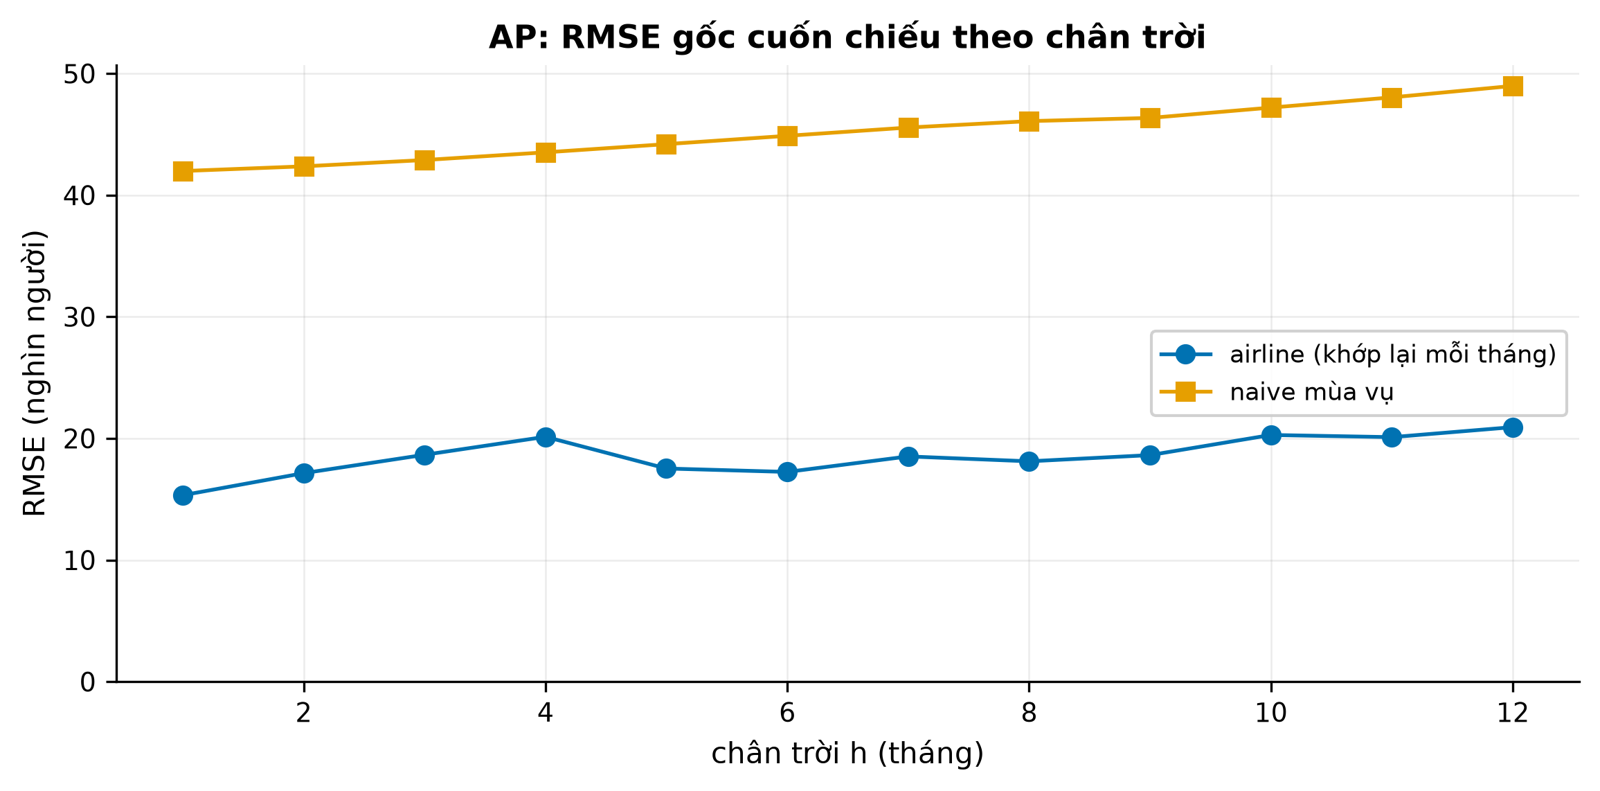

,RMSE (%),MAE (%)
"ARIMA(1,1,0) tham số cố định",1.439,1.094
"ARIMA(1,1,0) khớp lại mỗi 60 ngày",1.44,1.096
trôi cố định (δ̂ của 1500 ngày đầu),1.435,1.092
trôi cập nhật mỗi 60 ngày,1.435,1.092
naive,1.439,1.094


In [33]:
display(tab_ni)
display(tab_ap)
display(tab_ap1)
show_figure(fig_path)
tab_dp

### Phân tích và diễn giải

**TODO(nhóm):** viết 2–4 câu diễn giải kết quả ở trên, liên hệ trực tiếp với lý thuyết. Câu hỏi gợi ý:

- NI: bước chọn mô hình theo AIC trong từng gốc có làm sai số tăng/giảm so với cố định ARIMA(0,1,1)? Điều đó nói gì về độ lạc quan khi chọn mô hình trên chính dữ liệu báo cáo?
- AP: RMSE của airline tăng thế nào theo $h$, còn naive mùa vụ gần như phẳng do tăng trưởng hằng năm (trang 55 bài giảng)? So sánh gốc cuốn chiếu với kết quả 24 tháng giữ lại ở 12.11.
- DP: khớp lại định kỳ có khác tham số cố định không? Kết luận gì về 'mốc chuẩn khó vượt qua'?

### Nhận xét

**TODO(nhóm):** kết quả có phù hợp lý thuyết không? Nếu lệch, do đặc điểm nào của dữ liệu?

*Lưu ý:* DP dùng khớp lại theo khối 60 ngày (không khớp lại mỗi ngày) để giữ thời gian chạy hợp lý.

## 12.13 Hàm mất mát xác định phiếm hàm; kiểm định Diebold–Mariano

*Bộ dữ liệu:* AP (chính), NI

### Nội dung lý thuyết

**Định lý 6.** (a) $\arg\min_cE(Y-c)^2=EY$ và $\arg\min_cE|Y-c|$ là trung vị: RMSE nhắm tới trung bình, MAE nhắm tới trung vị; với dữ liệu lệch hai thước đo có thể xếp hạng khác nhau.
(d) Diebold–Mariano: $d_t=L(e_{1t})-L(e_{2t})$, $DM=\bar d/\sqrt{\hat v/m}\to N(0,1)$, $\hat v\approx\sum_{|k|<h}\hat\gamma_d(k)$ (Bài 11, Định lý 1); sai số $h$ bước là MA($h-1$) nên $\gamma_d(k)=0$ với $k\ge h$.
Kiểm định có thể hỏng với hai mô hình lồng nhau khớp trên cùng dữ liệu (Bài tập 10(4)).

### Cách triển khai

**[D]** AP: DM giữa airline và naive mùa vụ trên sai số một bước của gốc cuốn chiếu $t=120..143$ (hiệu bình phương, $t_{m-1}$ như bài giảng; thêm hiệu tuyệt đối); thứ hạng bốn phương pháp ở tập giữ lại 24 tháng theo RMSE và theo MAE;
hàm mất mát và phiếm hàm: cực tiểu của tổng bình phương và tổng tuyệt đối trên lưới $c$ cho số hành khách (lệch phải) so với trung bình và trung vị. NI: DM giữa ARIMA(0,1,1) và naive trên gốc cuốn chiếu $t=80..99$.

### Mã lệnh Python

In [34]:
ff_air = lambda tr, h: np.exp(airline(np.log(tr)).get_forecast(h).predicted_mean)
a1, f1 = E.rolling_origin_forecast(AP, ff_air, 120, 1); e_air = a1 - f1; e_sn = AP[120:144] - AP[108:132]
dm_sq, p_sq = E.diebold_mariano(e_air ** 2 - e_sn ** 2); dm_ab, p_ab = E.diebold_mariano(np.abs(e_air) - np.abs(e_sn))
ff_011 = lambda tr, h: ARIMA(tr, order=(0, 1, 1), trend="n").fit().forecast(h)
a_n, f_n = E.rolling_origin_forecast(NI, ff_011, 80, 1); e_a, e_nv = a_n - f_n, NI[80:] - NI[79:-1]
dm_ni_sq, p_ni_sq = E.diebold_mariano(e_a ** 2 - e_nv ** 2); dm_ni_ab, p_ni_ab = E.diebold_mariano(np.abs(e_a) - np.abs(e_nv))
tab_dm = save_table(pd.DataFrame([
    {"so sánh": "AP: airline − naive mùa vụ", "hàm mất mát": "bình phương", "số gốc m": len(e_air), "DM": dm_sq, "p (t_{m−1})": p_sq},
    {"so sánh": "AP: airline − naive mùa vụ", "hàm mất mát": "tuyệt đối", "số gốc m": len(e_air), "DM": dm_ab, "p (t_{m−1})": p_ab},
    {"so sánh": "NI: ARIMA(0,1,1) − naive", "hàm mất mát": "bình phương", "số gốc m": len(e_a), "DM": dm_ni_sq, "p (t_{m−1})": p_ni_sq},
    {"so sánh": "NI: ARIMA(0,1,1) − naive", "hàm mất mát": "tuyệt đối", "số gốc m": len(e_a), "DM": dm_ni_ab, "p (t_{m−1})": p_ni_ab}]).set_index(["so sánh", "hàm mất mát"]), "tab_b12_13_diebold_mariano")

In [35]:
tr_ap, te_ap = AP[:120], AP[120:]; f_air24 = np.exp(airline(np.log(tr_ap)).get_forecast(24).predicted_mean)
fcs = {"airline": f_air24, "naive mùa vụ": F.forecast_seasonal_naive(tr_ap, 24, 12), "trôi": F.forecast_drift(tr_ap, 24), "naive": F.forecast_naive(tr_ap, 24), "trung bình": F.forecast_mean(tr_ap, 24)}
rk = pd.DataFrame({"RMSE": {k: E.rmse(te_ap, f) for k, f in fcs.items()}, "MAE": {k: E.mae(te_ap, f) for k, f in fcs.items()}})
rk["hạng theo RMSE"] = rk["RMSE"].rank().astype(int); rk["hạng theo MAE"] = rk["MAE"].rank().astype(int); tab_rank = save_table(rk, "tab_b12_13_ranking")
grid = np.linspace(tr_ap.min(), tr_ap.max(), 4001)
mse = [np.mean((tr_ap - c) ** 2) for c in grid]; mae_ = [np.mean(np.abs(tr_ap - c)) for c in grid]
skew = stats.skew(tr_ap)
tab_fun = save_table(pd.DataFrame({"cực tiểu của hàm mất mát": [grid[np.argmin(mse)], grid[np.argmin(mae_)]], "đại lượng lý thuyết": [tr_ap.mean(), np.median(tr_ap)]},
                                  index=["tổng bình phương → trung bình", "tổng tuyệt đối → trung vị"]).assign(**{"độ lệch (skewness)": skew}), "tab_b12_13_loss_functional")

### Kết quả

In [36]:
display(tab_dm)
display(tab_rank)
tab_fun

số gốc m     DM  p (t_{m−1})
so sánh                    hàm mất mát                              
AP: airline − naive mùa vụ bình phương        24 -7.491    1.301e-07
                           tuyệt đối          24 -8.785    8.302e-09
NI: ARIMA(0,1,1) − naive   bình phương        20 -1.725       0.1008
                           tuyệt đối          20 -1.385       0.1822

,RMSE,MAE,hạng theo RMSE,hạng theo MAE
airline,43.18,39.44,1,1
naive mùa vụ,76.99,71.25,2,2
trôi,115.7,91.62,3,3
naive,137.3,115.2,4,4
trung bình,219.4,206.3,5,5


,cực tiểu của hàm mất mát,đại lượng lý thuyết,độ lệch (skewness)
tổng bình phương → trung bình,246,245.9,0.5819
tổng tuyệt đối → trung vị,233.1,233.5,0.5819


### Phân tích và diễn giải

**TODO(nhóm):** viết 2–4 câu diễn giải kết quả ở trên, liên hệ trực tiếp với lý thuyết. Câu hỏi gợi ý:

- DM của AP có tái lập −7.49, $p<10^{-6}$ không? Hiệu mất mát tuyệt đối có cho kết luận cùng chiều không?
- Hạng theo RMSE và theo MAE ở tập giữ lại có khác nhau không, và vì sao (liên hệ phiếm hàm trung bình/trung vị và dữ liệu lệch)?
- NI: khác biệt giữa ARIMA(0,1,1) và naive có ý nghĩa thống kê không với chỉ 20 gốc? Hạn chế khi mô hình lồng nhau?

### Nhận xét

**TODO(nhóm):** kết quả có phù hợp lý thuyết không? Nếu lệch, do đặc điểm nào của dữ liệu?

## 12.14 Checklist báo cáo dự báo ARIMA

*Bộ dữ liệu:* NI, AP, DP (cả 3)

### Nội dung lý thuyết

**Checklist (trang 66).** (1) Vẽ đồ thị, tách khối kiểm định → (2) biến đổi (log, Box–Cox) → (3) chọn $d,D$ (đồ thị, ACF, kiểm định) → (4) xác định $(p,q),(P,Q)$, khớp ML → (5) phần dư trắng? vượt mốc chuẩn?
Báo cáo: biến đổi và $d,D$ kèm bằng chứng và kiểm tra sai phân quá mức; mô hình khớp với SE, $\hat\sigma^2$, nhân quả và khả nghịch không triệt tiêu gần đúng; ACF phần dư, $Q_{LB}(H)$ với $H-p-q-P-Q$ bậc tự do,
ACF của bình phương phần dư; dự báo kèm khoảng và nêu rõ trung bình hay trung vị; độ chính xác so với mốc chuẩn tại chân trời có ý nghĩa, trên gốc cuốn chiếu.

### Cách triển khai

**[D]** Mỗi bộ một cột trong bảng checklist: NI ARIMA(0,1,1) khớp toàn bộ 100 năm (như bài giảng), AP airline (huấn luyện 120 tháng), DP bước ngẫu nhiên có trôi (huấn luyện 1500 ngày). Các số về độ chính xác lấy từ cùng thiết kế với 12.11–12.12
(NI: 20 năm cuối; AP: 24 tháng giữ lại; DP: 1 bước trên 360 ngày). Hình: ACF phần dư và ACF phần dư bình phương.

### Mã lệnh Python

In [37]:
def unit_root(y):
    a0, a1 = adfuller(y, regression="c")[1], adfuller(np.diff(y), regression="c")[1]
    fp = lambda q: "<0.0001" if q < 1e-4 else f"{q:.3g}"
    k0, k1 = kpss(y, regression="c", nlags="auto")[0], kpss(np.diff(y), regression="c", nlags="auto")[0]
    return f"ADF p-value: {fp(a0)} (y), {fp(a1)} (∇y); KPSS η: {k0:.2f} (y), {k1:.2f} (∇y), tới hạn 5% = 0.463"
models = {"NI": ARIMA(NI, order=(0, 1, 1), trend="n").fit(), "AP": airline(TR), "DP": ARIMA(LD[:DP_TRAIN_N], order=(0, 1, 0), trend="t").fit()}
spec = {"NI": dict(H=12, df=1, k=1, y=NI), "AP": dict(H=24, df=2, k=13, y=TR), "DP": dict(H=10, df=0, k=1, y=LD[:DP_TRAIN_N])}
ap_sd = lambda v: pd.Series(v).groupby(np.arange(len(v)) // 12).std(ddof=1)
out = {c: {} for c in models}; fig, axes = plt.subplots(3, 2, figsize=(11.5, 8.8))
for i, (c, f) in enumerate(models.items()):
    sp = spec[c]; e = F.zero_diffuse_residuals(f.resid, sp["k"]); roots_ar, roots_ma = np.abs(f.arroots), np.abs(f.maroots)
    q, p = lb(e, sp["H"], sp["df"]); q2, p2 = lb(e ** 2, sp["H"], 0)
    out[c]["1. Biến đổi"] = {"NI": "không", "AP": f"log (sd trong năm của mức tăng: {ap_sd(AP).min():.1f}–{ap_sd(AP).max():.1f}; của log: {ap_sd(LAP).min():.3f}–{ap_sd(LAP).max():.3f})",
                             "DP": "log giá"}[c]
    out[c]["2. d, D và bằng chứng"] = {"NI": "d = 1, D = 0; ", "AP": "d = 1, D = 1; ", "DP": "d = 1, D = 0; "}[c] + unit_root(sp["y"] if c != "AP" else TR[12:] - TR[:-12]) + (" (AP: kiểm định trên ∇₁₂)" if c == "AP" else "")
    w = np.diff(sp["y"], 2) if c != "AP" else np.diff(TR[12:] - TR[:-12])
    out[c]["3. Kiểm tra sai phân quá mức"] = f"ρ̂(1) của chuỗi đã sai phân (tối đa) = {A.sample_acf(np.diff(sp['y']) if c != 'AP' else w, 1)[1]:.3f}; ρ̂(1) sau khi sai phân thêm một lần = {A.sample_acf(np.diff(np.diff(sp['y']) if c != 'AP' else w), 1)[1]:.3f}"
    out[c]["4. Mô hình khớp (ML)"] = "; ".join(f"{PLAB.get(n, n)} = {v:.4g} (SE {se:.2g})" for n, v, se in zip(f.param_names, f.params, f.bse))
    out[c]["5. Nhân quả / khả nghịch"] = f"min|nghiệm AR| = {roots_ar.min() if len(roots_ar) else float('nan'):.3g}; min|nghiệm MA| = {roots_ma.min() if len(roots_ma) else float('nan'):.3g}"
    out[c]["6. Phần dư"] = f"Q_LB({sp['H']}) = {q:.2f}, df = {sp['H'] - sp['df']}, p = {p:.3f}; phần dư²: Q = {q2:.2f}, p = {p2:.3g}"
    acf_bars(axes[i, 0], A.sample_acf(e, 24), len(e), f"{c}: ACF của phần dư"); acf_bars(axes[i, 1], A.sample_acf(e ** 2, 24), len(e), f"{c}: ACF của phần dư²"); panel_label(axes[i, 0], "(" + "abc"[i] + ")")
fig.tight_layout(); fig_path = save_figure(fig, "fig_b12_14_residual_acf")
# dự báo và so với mốc chuẩn
fc_ni = models["NI"].get_forecast(10); ci = fc_ni.conf_int(); out["NI"]["7. Dự báo + khoảng (thang gốc, đã là trung bình=trung vị)"] = f"h=1: {fc_ni.predicted_mean[0]:.0f} [{ci[0, 0]:.0f}, {ci[0, 1]:.0f}]; h=10: {fc_ni.predicted_mean[9]:.0f} [{ci[9, 0]:.0f}, {ci[9, 1]:.0f}]"
g = models["AP"].get_forecast(24); bt = F.back_transform_log(g.predicted_mean, np.sqrt(g.var_pred_mean))
out["AP"]["7. Dự báo + khoảng (thang gốc, đã là trung bình=trung vị)"] = f"trung vị/trung bình (1/1959): {bt['median'][0]:.1f}/{bt['mean'][0]:.1f} [{bt['lower'][0]:.0f}, {bt['upper'][0]:.0f}]; (12/1960): {bt['median'][23]:.1f}/{bt['mean'][23]:.1f} [{bt['lower'][23]:.0f}, {bt['upper'][23]:.0f}]"
gd = models["DP"].get_forecast(20); sd = np.sqrt(gd.var_pred_mean[[0, 19]]); b2 = F.back_transform_log(gd.predicted_mean[[0, 19]], sd)
out["DP"]["7. Dự báo + khoảng (thang gốc, đã là trung bình=trung vị)"] = f"h=1: trung vị {np.exp(gd.predicted_mean[0]):.0f}, trung bình {b2['mean'][0]:.0f}; h=20: trung vị {b2['median'][1]:.0f}, trung bình {b2['mean'][1]:.0f} [{b2['lower'][1]:.0f}, {b2['upper'][1]:.0f}]"
ni_tr = ARIMA(NI[:80], order=(0, 1, 1), trend="n").fit().forecast(20); sn = F.forecast_seasonal_naive(AP[:120], 24, 12)
af = np.exp(airline(np.log(AP[:120])).get_forecast(24).predicted_mean)
out["NI"]["8. So với mốc chuẩn"] = f"RMSE 20 năm cuối: ARIMA {E.rmse(NI[80:], ni_tr):.1f} vs naive {E.rmse(NI[80:], F.forecast_naive(NI[:80], 20)):.1f}"
out["AP"]["8. So với mốc chuẩn"] = f"RMSE 24 tháng: airline {E.rmse(AP[120:], af):.1f} vs naive mùa vụ {E.rmse(AP[120:], sn):.1f}; MASE {E.mase(AP[120:], af, AP[:120], 12):.2f}"
tl, te = LD[:DP_TRAIN_N], LD[DP_TRAIN_N:]
out["DP"]["8. So với mốc chuẩn"] = f"RMSE 1 bước (%): trôi {100 * E.rmse(te, LD[DP_TRAIN_N - 1:-1] + (tl[-1] - tl[0]) / (DP_TRAIN_N - 1)):.3f} vs naive {100 * E.rmse(te, LD[DP_TRAIN_N - 1:-1]):.3f}"
tab = save_table(pd.DataFrame(out), "tab_b12_14_checklist")

### Kết quả

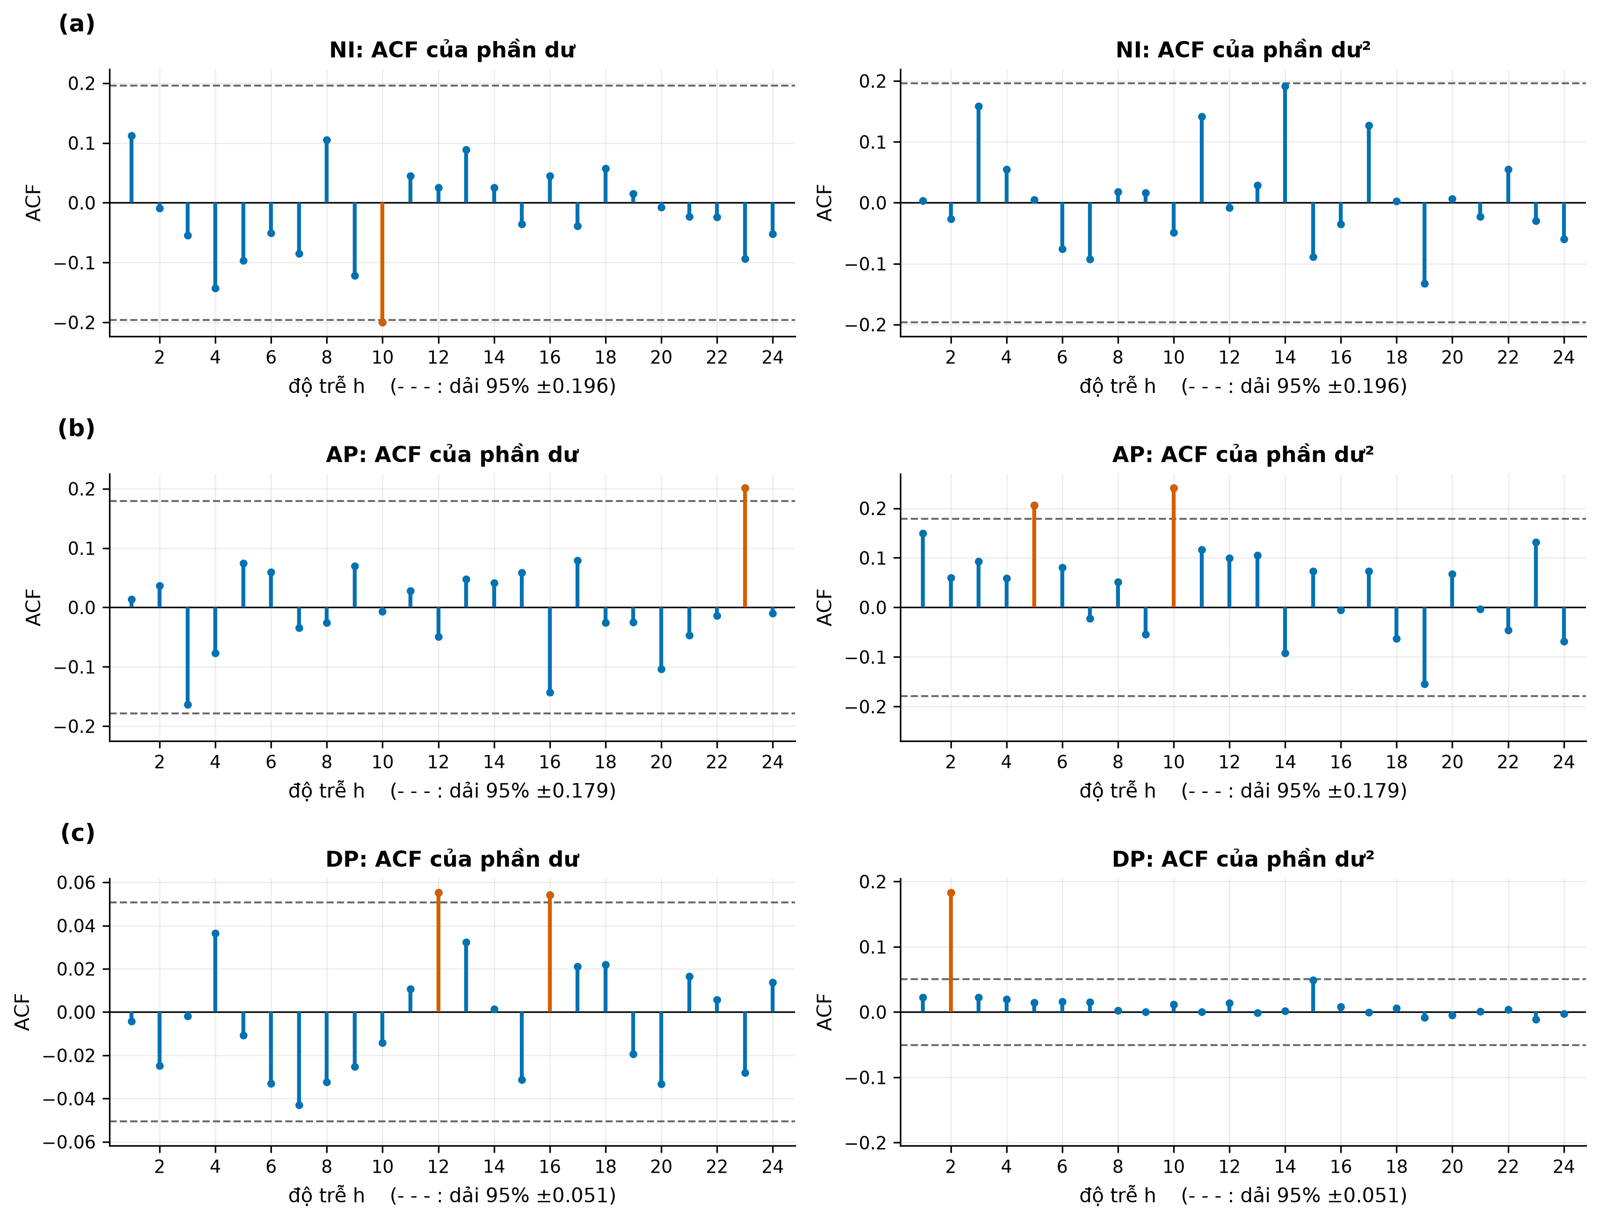

,NI,AP,DP
1. Biến đổi,không,log (sd trong năm của mức tăng: 13.7–77.7; của log: 0.108–0.160),log giá
"2. d, D và bằng chứng","d = 1, D = 0; ADF p-value: 0.00118 (y), <0.0001 (∇y); KPSS η: 0.87 (y), 0.12 (∇y), tới hạn 5% = 0.463","d = 1, D = 1; ADF p-value: 0.405 (y), 0.00139 (∇y); KPSS η: 0.33 (y), 0.14 (∇y), tới hạn 5% = 0.463 (AP: kiểm định trên ∇₁₂)","d = 1, D = 0; ADF p-value: 0.991 (y), <0.0001 (∇y); KPSS η: 5.05 (y), 0.25 (∇y), tới hạn 5% = 0.463"
3. Kiểm tra sai phân quá mức,ρ̂(1) của chuỗi đã sai phân (tối đa) = -0.402; ρ̂(1) sau khi sai phân thêm một lần = -0.626,ρ̂(1) của chuỗi đã sai phân (tối đa) = -0.328; ρ̂(1) sau khi sai phân thêm một lần = -0.660,ρ̂(1) của chuỗi đã sai phân (tối đa) = -0.004; ρ̂(1) sau khi sai phân thêm một lần = -0.490
4. Mô hình khớp (ML),θ = -0.7334 (SE 0.074); σ² = 2.06e+04 (SE 2.9e+03),θ = -0.3425 (SE 0.087); Θ (mùa vụ) = -0.5406 (SE 0.1); σ² = 0.001402 (SE 0.00018),c (độ trôi) = 0.0004875 (SE 0.00024); σ² = 8.208e-05 (SE 1.2e-06)
5. Nhân quả / khả nghịch,min|nghiệm AR| = nan; min|nghiệm MA| = 1.36,min|nghiệm AR| = nan; min|nghiệm MA| = 1.05,min|nghiệm AR| = nan; min|nghiệm MA| = nan
6. Phần dư,"Q_LB(12) = 13.57, df = 11, p = 0.258; phần dư²: Q = 7.27, p = 0.839","Q_LB(24) = 19.76, df = 22, p = 0.598; phần dư²: Q = 35.15, p = 0.0662","Q_LB(10) = 10.43, df = 10, p = 0.404; phần dư²: Q = 53.68, p = 5.57e-08"
"7. Dự báo + khoảng (thang gốc, đã là trung bình=trung vị)","h=1: 799 [517, 1080]; h=10: 799 [438, 1159]","trung vị/trung bình (1/1959): 348.6/348.8 [324, 375]; (12/1960): 388.2/392.8 [286, 526]","h=1: trung vị 3409, trung bình 3410; h=20: trung vị 3441, trung bình 3444 [3179, 3726]"
8. So với mốc chuẩn,RMSE 20 năm cuối: ARIMA 122.8 vs naive 123.1,RMSE 24 tháng: airline 43.2 vs naive mùa vụ 77.0; MASE 1.38,RMSE 1 bước (%): trôi 1.435 vs naive 1.439


In [38]:
show_figure(fig_path)
pd.set_option('display.max_colwidth', None)
tab

### Phân tích và diễn giải

**TODO(nhóm):** viết 2–4 câu diễn giải kết quả ở trên, liên hệ trực tiếp với lý thuyết. Câu hỏi gợi ý:

- Mỗi ô của bảng checklist đã đủ bằng chứng cho từng bộ chưa? Bộ nào còn thiếu (ví dụ NI: ADF và KPSS mâu thuẫn do đổi mức 1899)?
- DP: phần dư trắng nhưng phần dư bình phương thì sao? Hệ quả với khoảng dự báo (bài giảng: 'đổi mới có đuôi nặng hơn chuẩn', cụm biến động) và giới hạn của ARIMA (chỉ nhắc GARCH, không khớp).
- Báo cáo dự báo của nhóm đã nêu rõ trung bình hay trung vị, chân trời, mốc chuẩn và thiết kế gốc cuốn chiếu chưa?

### Nhận xét

**TODO(nhóm):** kết quả có phù hợp lý thuyết không? Nếu lệch, do đặc điểm nào của dữ liệu?

## ⋆ Mở rộng (tùy chọn): hồi quy giả tạo và đồng tích hợp log DAX ~ log SMI

*Bộ dữ liệu:* DAX và SMI (phần mở rộng, không thuộc 6 bộ chính)

### Nội dung lý thuyết

Hai chuỗi I(1) $X_t,Y_t$ đồng tích hợp nếu $Y_t-\beta X_t$ là I(0) (Engle–Granger, 1987). $R^2$ cao không phải là đồng tích hợp: hồi quy log DAX theo log SMI (1991–1998) cho $\hat\beta=0.820$, $R^2=0.965$ nhưng
kiểm định Engle–Granger trên phần dư có $p=0.28$ (bài giảng, trang ⋆). *Phần mở rộng:* SMI chỉ dùng ở đây và phải được ghi chú là mở rộng.

### Cách triển khai

OLS $\log\mathrm{DAX}\sim\log\mathrm{SMI}$ rồi kiểm định Engle–Granger (`statsmodels.tsa.stattools.coint`). Chỉ đọc cột SMI từ file gốc `data/raw/EuStockMarkets.csv`.

### Mã lệnh Python

In [39]:
from as3179ts.data import load_raw
raw = load_raw("EuStockMarkets"); x, y = np.log(raw["SMI"].to_numpy()), np.log(raw["DAX"].to_numpy())
ols = sm.OLS(y, sm.add_constant(x)).fit(); eg = coint(y, x)
tab_ext = save_table(pd.DataFrame({"giá trị": [ols.params[1], ols.rsquared, eg[0], eg[1]]}, index=["β̂", "R²", "thống kê Engle–Granger", "p-value Engle–Granger"]), "tab_b12_ext_cointegration")

### Kết quả

In [40]:
tab_ext

,giá trị
β̂,0.8203
R²,0.965
thống kê Engle–Granger,-2.502
p-value Engle–Granger,0.2781


### Phân tích và diễn giải

**TODO(nhóm):** viết 2–4 câu diễn giải kết quả ở trên, liên hệ trực tiếp với lý thuyết. Câu hỏi gợi ý:

- $R^2$ rất cao nhưng Engle–Granger không bác bỏ 'không đồng tích hợp': diễn giải thế nào (liên hệ hồi quy giả mạo ở 12.2)?

### Nhận xét

**TODO(nhóm):** kết quả có phù hợp lý thuyết không? Nếu lệch, do đặc điểm nào của dữ liệu?

## Bảng tổng hợp: ID × bộ dữ liệu → phù hợp lý thuyết?

Nguyên liệu cho Mục 4.6 của báo cáo (Bài 12). Điền cột cuối sau khi viết xong các nhận xét.

| ID | Nội dung | Bộ | Phù hợp lý thuyết? |
|---|---|---|---|
| 12.1 | Xu thế tất định và xu thế ngẫu nhiên; I(d) | NI, AP, DP (cả 3) | **TODO(nhóm)** |
| 12.2 | Bước ngẫu nhiên | DP (mô phỏng, tham số từ DP); NI, AP: giải thích | **TODO(nhóm)** |
| 12.3 | Sai phân sửa được gì và làm hỏng gì: sai phân quá mức | NI, DP (AP: xem 12.10) | **TODO(nhóm)** |
| 12.4 | Kiểm định nghiệm đơn vị: ADF và KPSS | NI, AP, DP (cả 3) + mô phỏng | **TODO(nhóm)** |
| 12.5 | Mô hình ARIMA(p, d, q) và độ trôi | NI, DP (AP: xem 12.10) | **TODO(nhóm)** |
| 12.6 | Ảnh hưởng vĩnh viễn của cú sốc: trọng số Ψ | NI, DP (AP: giải thích) | **TODO(nhóm)** |
| 12.7 | ARIMA(0,1,1) ≡ làm trơn mũ đơn ≡ mô hình mức cục bộ | NI (chính); DP, AP: giải thích | **TODO(nhóm)** |
| 12.8 | Dự báo h bước tối ưu MSE, phương sai sai số và khoảng dự báo | NI, AP, DP (cả 3) + mô phỏng độ phủ | **TODO(nhóm)** |
| 12.9 | Dự báo trên thang log: trung vị, trung bình, khoảng chuyển đổi | AP, DP (NI: không biến đổi) | **TODO(nhóm)** |
| 12.10 | Sai phân mùa vụ, SARIMA và mô hình airline | AP | **TODO(nhóm)** |
| 12.11 | Mốc chuẩn và thước đo độ chính xác | NI, AP, DP (cả 3) | **TODO(nhóm)** |
| 12.12 | Thẩm định trên gốc cuốn chiếu và vai trò của bước chọn mô hình | NI, AP, DP (cả 3) | **TODO(nhóm)** |
| 12.13 | Hàm mất mát xác định phiếm hàm; kiểm định Diebold–Mariano | AP (chính), NI | **TODO(nhóm)** |
| 12.14 | Checklist báo cáo dự báo ARIMA | NI, AP, DP (cả 3) | **TODO(nhóm)** |
| ⋆ | Mở rộng (tùy chọn): hồi quy giả tạo và đồng tích hợp log DAX ~ log SMI | DAX và SMI (phần mở rộng, không thuộc 6 bộ chính) | **TODO(nhóm)** |